<a href="https://colab.research.google.com/github/sarayukammari/Grammer_scoring/blob/main/grammar_scoring_final_cleaned.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Grammar Scoring Engine for Spoken Audio — v1 → v4 (clean, complete notebook)
**SHL Hiring Assessment 2026** — predict a continuous MOS-Likert grammar score (0–5) from a 45–60 s speech sample.

**Runtime:** Colab → *Runtime ▸ Change runtime type ▸ T4 GPU*, then *Run all*. Everything expensive is cached in `/content/work`, so a re-run takes minutes. First run ≈ 90 min on a T4 (Whisper transcription ≈ 25 min, encoders ≈ 25 min, models ≈ 30 min).

## Roadmap
| Part | Stack | What it adds |
|---|---|---|
| A | **v1** | Whisper transcripts → acoustic / syntax / GPT-2 / CoLA features; wav2vec2 and sentence embeddings; Ridge + LightGBM + CatBoost + SVR → non-negative stack |
| B | **v2** | Repeated CV, diagnostics, Whisper-small encoder + layer sweep, tuned SVR, regularised LightGBM |
| C | **v3** | Duration-aware folds and a test-mix weighted metric, per-minute rates, averaged layers, joint SVR, extra decorrelated members |
| D | **v4** | Larger Whisper encoder (mean+std, frame cache), importance-weighted and crop-augmented SVRs, attentive-pooling head, weighted stackers |
| – | **Comparison + report** | all four stacks scored identically, submissions, report |

**Reference results from earlier runs:** v1 CV RMSE 0.5314 (Kaggle public 0.4130); v3 CV RMSE 0.4915, test-mix weighted 0.5519 (Kaggle public 0.4087).

> Every stack is finally re-scored on the **same repeated, duration-aware folds**, so the v1→v3 and v3→v4 differences in Part D are like-for-like. Numbers inside Parts B and C use the fold schemes in force when they were developed.

# Part A — v1: baseline pipeline

## 1. Setup & data download

In [4]:
# Install dependencies (quiet). ~1-2 min.
!pip install -q faster-whisper sentence-transformers transformers accelerate librosa soundfile spacy textstat lightgbm catboost kaggle nvidia-cublas-cu12 "nvidia-cudnn-cu12>=9,<10"
!python -m spacy download en_core_web_sm -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 88.9 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [5]:
import os, re, gc, glob, json, math, time, zipfile, warnings, subprocess
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import soundfile as sf
import librosa
import librosa.display
from tqdm.auto import tqdm
from IPython.display import display, Markdown

import torch
from scipy.stats import pearsonr, spearmanr
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# ---------------- configuration ----------------
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
WHISPER_MODEL = "medium.en"      # use "small.en" for a faster (slightly less accurate) run
SR = 16000                       # all audio is processed at 16 kHz mono
WORK = "/content/work"           # cache directory (features, transcripts, embeddings)
os.makedirs(WORK, exist_ok=True)
print("Device:", DEVICE, "| Whisper model:", WHISPER_MODEL)
if DEVICE == "cpu":
    print("WARNING: no GPU detected - transcription will be very slow. Switch the runtime to a GPU.")

Device: cuda | Whisper model: medium.en


**Kaggle credentials.** Don't paste your token into the notebook (anyone you share the notebook with could use it).
In Colab, open the 🔑 *Secrets* panel, add a secret named `KAGGLE_API_TOKEN`, and enable notebook access. You also need to have
*joined the competition* on Kaggle (accepted the rules) or the download will return a 403.

In [6]:
COMP = "shl-hiring-assessment-2026"
DATA_ROOT = "/content/grammar_data"

def find_base(root):
    hits = glob.glob(f"{root}/**/train.csv", recursive=True)
    return os.path.dirname(hits[0]) if hits else None

BASE = find_base(DATA_ROOT) or find_base("/kaggle/input")   # also works inside a Kaggle notebook

if BASE is None:
    # ---- 1. get the token ----
    token = None
    try:
        from google.colab import userdata
        token = userdata.get("KAGGLE_API_TOKEN")
    except Exception as e:
        print("Colab secret not readable:", type(e).__name__, "-", e)
    if not token:
        import getpass
        token = getpass.getpass("Paste your Kaggle API token: ")
    token = token.strip().strip("'\"")            # remove whitespace / accidental quotes
    print("Token length:", len(token))                          # sanity check only; never print the token itself

    # ---- 2. give it to the CLI BOTH ways (env var + ~/.kaggle/access_token) ----
    os.environ["KAGGLE_API_TOKEN"] = token
    kdir = os.path.expanduser("~/.kaggle"); os.makedirs(kdir, exist_ok=True)
    with open(f"{kdir}/access_token", "w") as fh: fh.write(token)
    os.chmod(f"{kdir}/access_token", 0o600)

    # ---- 3. download + unzip ----
    os.makedirs(DATA_ROOT, exist_ok=True)
    r = subprocess.run(["kaggle", "competitions", "download", COMP, "-p", DATA_ROOT],
                       capture_output=True, text=True, env=os.environ.copy())
    print("download rc:", r.returncode); print(r.stdout[-800:]); print(r.stderr[-800:])
    assert r.returncode == 0, "Download failed - read the output above."

    for z in glob.glob(f"{DATA_ROOT}/*.zip"):
        with zipfile.ZipFile(z) as zf:
            zf.extractall(DATA_ROOT)
    BASE = find_base(DATA_ROOT)

assert BASE is not None, "train.csv not found - check the download / competition access."
TRAIN_AUDIO, TEST_AUDIO = f"{BASE}/train", f"{BASE}/test"
print("BASE:", BASE)
print("Contents:", os.listdir(BASE))
print("Train audio files:", len(os.listdir(TRAIN_AUDIO)), "| Test audio files:", len(os.listdir(TEST_AUDIO)))

Token length: 37
download rc: 0


B/s]
 94%|█████████▍| 1.15G/1.22G [00:29<00:01, 44.7MB/s]
 95%|█████████▍| 1.16G/1.22G [00:29<00:01, 43.1MB/s]
 95%|█████████▌| 1.16G/1.22G [00:29<00:01, 45.0MB/s]
 96%|█████████▌| 1.17G/1.22G [00:29<00:01, 43.5MB/s]
 96%|█████████▌| 1.17G/1.22G [00:29<00:01, 44.9MB/s]
 97%|█████████▋| 1.18G/1.22G [00:29<00:01, 43.7MB/s]
 97%|█████████▋| 1.18G/1.22G [00:30<00:00, 41.5MB/s]
 97%|█████████▋| 1.19G/1.22G [00:30<00:01, 36.2MB/s]
 98%|█████████▊| 1.19G/1.22G [00:30<00:00, 38.9MB/s]
 98%|█████████▊| 1.20G/1.22G [00:30<00:00, 40.1MB/s]
 99%|█████████▊| 1.21G/1.22G [00:30<00:00, 41.7MB/s]
 99%|█████████▉| 1.21G/1.22G [00:30<00:00, 42.1MB/s]
 99%|█████████▉| 1.22G/1.22G [00:30<00:00, 43.1MB/s]
100%|█████████▉| 1.22G/1.22G [00:31<00:00, 42.3MB/s]
100%|██████████| 1.22G/1.22G [00:31<00:00, 42.2MB/s]

BASE: /content/grammar_data/Dataset_Final
Contents: ['sample_submission.csv', 'train.csv', 'test', 'train', 'test.csv']
Train audio files: 769 | Test audio files: 21

In [7]:
train_df = pd.read_csv(f"{BASE}/train.csv")
test_df  = pd.read_csv(f"{BASE}/test.csv")
sample_df = pd.read_csv(f"{BASE}/sample_submission.csv")

for name, d in [("train", train_df), ("test", test_df), ("sample_submission", sample_df)]:
    print(f"{name:18s} shape={d.shape}  columns={d.columns.tolist()}")

# NOTE: train/ and test/ are separate folders and may reuse the same file names
# (e.g. audio_17.wav exists in both, with different audio). Every cache below is therefore keyed by 'split/filename'.
train_df["split"], test_df["split"] = "train", "test"
train_df["key"] = "train/" + train_df["filename"]
test_df["key"]  = "test/"  + test_df["filename"]
train_df["path"] = TRAIN_AUDIO + "/" + train_df["filename"]
test_df["path"]  = TEST_AUDIO  + "/" + test_df["filename"]

# ---- sanity checks ----
print("\nMissing values  - train:", int(train_df[["filename","label"]].isna().sum().sum()), "| test:", int(test_df["filename"].isna().sum()))
print("Duplicate files - train:", int(train_df["filename"].duplicated().sum()), "| test:", int(test_df["filename"].duplicated().sum()))
print("Missing audio   - train:", int((~train_df["path"].map(os.path.exists)).sum()), "| test:", int((~test_df["path"].map(os.path.exists)).sum()))
print("Test label column is a placeholder:", test_df["label"].unique()[:5])

# sample_submission is only a format reference; check whether it matches test.csv
print("\nsample_submission rows:", len(sample_df), "| test.csv rows:", len(test_df),
      "| filenames in both:", len(set(sample_df['filename']) & set(test_df['filename'])))
display(train_df.head())

train              shape=(769, 2)  columns=['filename', 'label']
test               shape=(216, 2)  columns=['filename', 'label']
sample_submission  shape=(204, 2)  columns=['filename', 'label']

Missing values  - train: 0 | test: 0
Duplicate files - train: 0 | test: 0
Missing audio   - train: 0 | test: 0
Test label column is a placeholder: [-1]

sample_submission rows: 204 | test.csv rows: 216 | filenames in both: 25


,filename,label,split,key,path
0,audio_192.wav,3.0,train,train/audio_192.wav,/content/grammar_data/Dataset_Final/train/audi...
1,audio_436.wav,3.0,train,train/audio_436.wav,/content/grammar_data/Dataset_Final/train/audi...
2,audio_447.wav,3.5,train,train/audio_447.wav,/content/grammar_data/Dataset_Final/train/audi...
3,audio_126.wav,2.0,train,train/audio_126.wav,/content/grammar_data/Dataset_Final/train/audi...
4,audio_61.wav,2.0,train,train/audio_61.wav,/content/grammar_data/Dataset_Final/train/audi...


## 2. Exploratory data analysis

count    769.000
mean       3.313
std        1.239
min        0.000
25%        2.500
50%        3.000
75%        4.000
max        5.000

Count per score:
 label
0.0     37
1.0      1
1.5      3
2.0    102
2.5     79
3.0    174
3.5     64
4.0    124
4.5     52
5.0    133


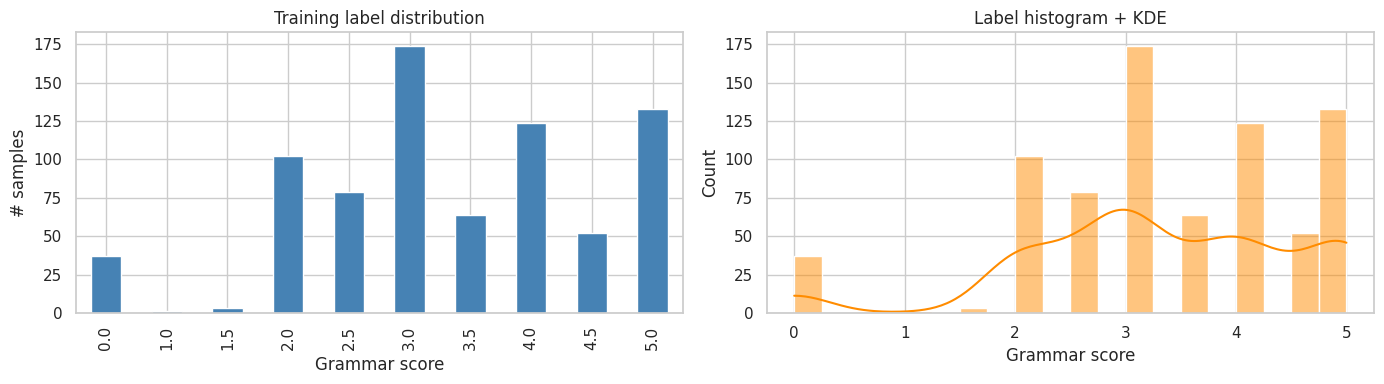

In [8]:
y_all = train_df["label"].values
print(train_df["label"].describe().round(3).to_string())
print("\nCount per score:\n", train_df["label"].value_counts().sort_index().to_string())

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
train_df["label"].value_counts().sort_index().plot(kind="bar", ax=ax[0], color="steelblue")
ax[0].set(title="Training label distribution", xlabel="Grammar score", ylabel="# samples")
sns.histplot(train_df["label"], bins=20, kde=True, ax=ax[1], color="darkorange")
ax[1].set(title="Label histogram + KDE", xlabel="Grammar score")
plt.tight_layout(); plt.show()

**Observation:** the labels are not uniform — there is a spike at **0** (37 samples), almost nothing at 1 / 1.5, and the half-point scores (2.5, 3.5, 4.5) exist, i.e. labels are averages of several raters.
The score-0 group is probably silent / unintelligible / non-English audio, which we will check below. Because errors on these are large, a good model must detect them.

s                   test     train
duration count    216.00    769.00
         mean      48.76     55.78
         std        8.18      7.91
         min        6.48     20.06
         25%       45.06     54.19
         50%       45.06     60.07
         75%       60.01     60.07
         max       61.03     61.04
orig_sr  count    216.00    769.00
         mean   16000.00  16000.00
         std        0.00      0.00
         min    16000.00  16000.00
         25%    16000.00  16000.00
         50%    16000.00  16000.00
         75%    16000.00  16000.00
         max    16000.00  16000.00
channels count    216.00    769.00
         mean       1.00      1.00
         std        0.00      0.00
         min        1.00      1.00
         25%        1.00      1.00
         50%        1.00      1.00
         75%        1.00      1.00
         max        1.00      1.00


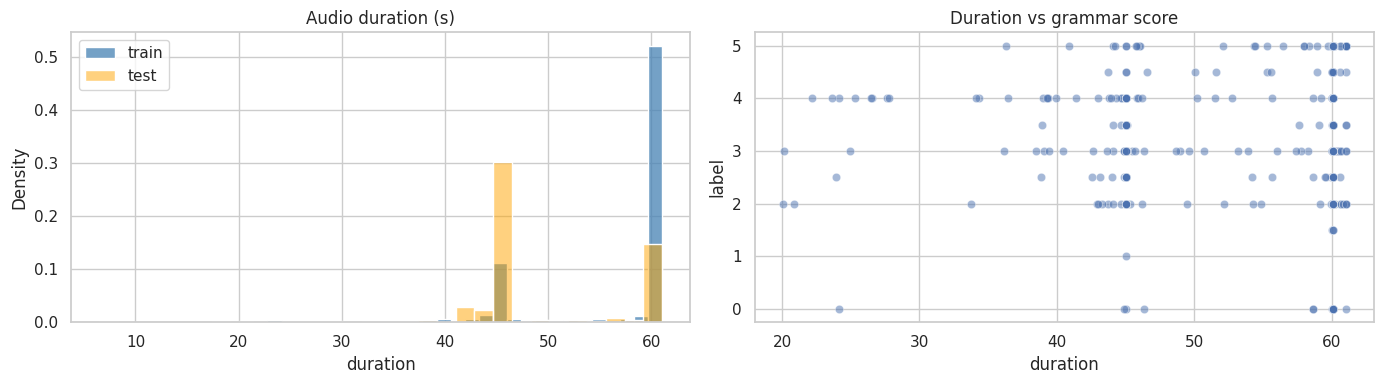

In [9]:
# Audio metadata for every file (fast: header only)
def meta(path):
    i = sf.info(path)
    return i.duration, i.samplerate, i.channels

for d in (train_df, test_df):
    m = d["path"].map(meta)
    d["duration"] = [x[0] for x in m]; d["orig_sr"] = [x[1] for x in m]; d["channels"] = [x[2] for x in m]

print(pd.concat([train_df.assign(s="train"), test_df.assign(s="test")]).groupby("s")[["duration","orig_sr","channels"]].describe().T.round(2).to_string())

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(train_df["duration"], color="steelblue", label="train", ax=ax[0], stat="density", bins=30)
sns.histplot(test_df["duration"],  color="orange",    label="test",  ax=ax[0], stat="density", bins=30, alpha=.5)
ax[0].set(title="Audio duration (s)"); ax[0].legend()
sns.scatterplot(data=train_df, x="duration", y="label", alpha=.5, ax=ax[1])
ax[1].set(title="Duration vs grammar score")
plt.tight_layout(); plt.show()

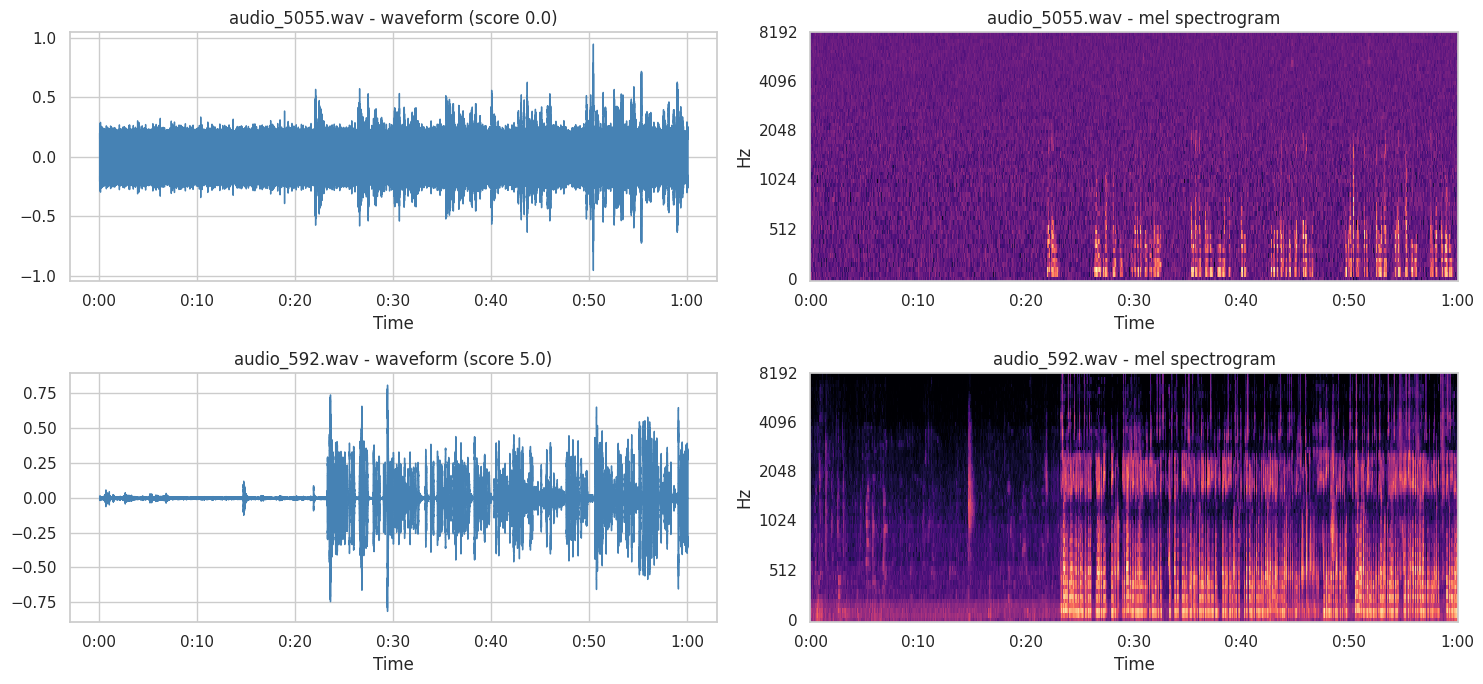

In [10]:
# Waveform + mel-spectrogram of one low-score and one high-score sample
low  = train_df[train_df.label <= 1].iloc[0]
high = train_df[train_df.label == 5].iloc[0]
fig, axes = plt.subplots(2, 2, figsize=(15, 7))
for r, (name, row) in enumerate([("low", low), ("high", high)]):
    y, _ = librosa.load(row.path, sr=SR)
    librosa.display.waveshow(y, sr=SR, ax=axes[r, 0], color="steelblue")
    axes[r, 0].set_title(f"{row.filename} - waveform (score {row.label})")
    S = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=SR, n_mels=64), ref=np.max)
    librosa.display.specshow(S, sr=SR, x_axis="time", y_axis="mel", ax=axes[r, 1])
    axes[r, 1].set_title(f"{row.filename} - mel spectrogram")
plt.tight_layout(); plt.show()

## 3. Speech-to-text and acoustic features

**Why transcribe?** The rubric is about *sentence structure, syntax and grammatical control*, which lives in the words that were said, not in the acoustics. So the core of the pipeline is:
audio → ASR transcript → grammar/linguistic features. Acoustic and fluency features (pauses, speech rate, ASR confidence) are added as complementary signals, since hesitant, fragmentary speech correlates with lower grammar scores.

**Design choices for ASR (Whisper via `faster-whisper`):**
* `condition_on_previous_text=False` and no prompt, so the model is less inclined to "autocorrect" the speaker's grammar using earlier context.
* Word-level timestamps and probabilities are kept; low-confidence words often coincide with unclear / ungrammatical speech.
* Results are cached to disk (JSON), so a crash or re-run doesn't repeat ~20 min of GPU work.

In [11]:
from faster_whisper import WhisperModel

def preload_cuda12():
    """Make the pip-installed CUDA-12 libraries visible to ctranslate2 (faster-whisper's backend)."""
    import ctypes, site
    if DEVICE != "cuda": return
    roots = set(site.getsitepackages() + [site.getusersitepackages()])
    for pat in ("nvidia/cublas/lib/libcublasLt.so.12*", "nvidia/cublas/lib/libcublas.so.12*", "nvidia/cudnn/lib/libcudnn.so.9*"):
        for root in roots:
            hits = sorted(glob.glob(f"{root}/{pat}"))
            if hits:
                try:
                    ctypes.CDLL(hits[0], mode=ctypes.RTLD_GLOBAL); print("loaded", os.path.basename(hits[0]))
                except OSError as e:
                    print("could not load", hits[0], e)
                break

def load_asr():
    try:
        m = WhisperModel(WHISPER_MODEL, device=DEVICE, compute_type="float16" if DEVICE == "cuda" else "int8")
        list(m.transcribe(np.zeros(SR, dtype=np.float32), language="en")[0])        # smoke test (fails fast if CUDA libs are broken)
        return m
    except Exception as e:
        print("ASR GPU load/smoke test failed:", e, "\n-> falling back to small.en on CPU (slow!)")
        return WhisperModel("small.en", device="cpu", compute_type="int8")

all_df = pd.concat([train_df, test_df], ignore_index=True)
TRANSCRIPT_FILE = f"{WORK}/transcripts_{WHISPER_MODEL}.json"
transcripts = json.load(open(TRANSCRIPT_FILE)) if os.path.exists(TRANSCRIPT_FILE) else {}

# if a previous run failed systematically, its cache is full of empty entries -> drop them so they get retried
bad = [k for k, v in transcripts.items() if v["text"] == "" and not v["words"] and v["no_speech_prob"] == 1.0]
if len(bad) > 20:
    for k in bad: del transcripts[k]
    print(f"Purged {len(bad)} empty cache entries from a failed run")

todo = all_df[~all_df["key"].isin(transcripts)]
print(f"{len(transcripts)} cached transcripts, {len(todo)} to transcribe")

if len(todo):
    preload_cuda12()
    asr = load_asr()

    def transcribe_one(path):
        audio, _ = librosa.load(path, sr=SR, mono=True)             # decode with librosa (bypasses PyAV)
        def run(word_ts):
            segments, _ = asr.transcribe(audio, language="en", beam_size=5, word_timestamps=word_ts,
                                         condition_on_previous_text=False, temperature=0.0)
            texts, words, lps, nsp = [], [], [], []
            for seg in segments:                                    # the generator is consumed here, so errors surface here
                texts.append(seg.text.strip()); lps.append(seg.avg_logprob); nsp.append(seg.no_speech_prob)
                for w in (seg.words or []):
                    words.append([w.word.strip(), float(w.start), float(w.end), float(w.probability)])
            return {"text": " ".join(texts).strip(), "words": words,
                    "avg_logprob": float(np.mean(lps)) if lps else -5.0,
                    "no_speech_prob": float(np.mean(nsp)) if nsp else 1.0}
        try:
            return run(True)
        except Exception:
            return run(False)                                       # fallback: text only (no word timings)

    n_fail = 0
    for n, (_, row) in enumerate(tqdm(todo.iterrows(), total=len(todo), desc="Transcribing")):
        try:
            transcripts[row.key] = transcribe_one(row.path)
        except Exception as e:
            n_fail += 1; print("ASR failed for", row.key, "->", e)  # not cached -> retried on the next run
            if n_fail >= 10:
                raise RuntimeError("10 ASR failures - stopping so empty transcripts don't pollute the features.")
        if n % 50 == 0:
            json.dump(transcripts, open(TRANSCRIPT_FILE, "w"))
    json.dump(transcripts, open(TRANSCRIPT_FILE, "w"))
    del asr; gc.collect(); torch.cuda.empty_cache()

for k in all_df["key"]:                                             # placeholder for any clip that still has none
    transcripts.setdefault(k, {"text": "", "words": [], "avg_logprob": -5.0, "no_speech_prob": 1.0})

train_df["text"] = train_df["key"].map(lambda k: transcripts[k]["text"])
test_df["text"] = test_df["key"].map(lambda k: transcripts[k]["text"])
print("Empty transcripts - train:", int((train_df.text.str.len() == 0).sum()), "| test:", int((test_df.text.str.len() == 0).sum()))

0 cached transcripts, 985 to transcribe
loaded libcublasLt.so.12
loaded libcublas.so.12
loaded libcudnn.so.9


Transcribing:   0%|          | 0/985 [00:00<?, ?it/s]

Empty transcripts - train: 0 | test: 0


In [12]:
# Look at transcripts from different score levels
for lab in [0, 2, 3, 4, 5]:
    r = train_df[train_df.label == lab].iloc[0]
    print(f"--- score {lab} | {r.filename} ---\n{r.text[:500]}\n")

--- score 0 | audio_5055.wav ---
When pedaling, the wind blows on my skin. Since then, I've tried to change my day every time I leave my home. I could make myself forget a piece of whatever is left into an accident, but just blocking my heart so that I have peace and let's go home

--- score 2 | audio_126.wav ---
and once upon a time we with 5 friends went on a tour with a travel agent phenomenally and we stayed on a resort and we stayed around we stayed at a resort and after that we stayed when we checked in in the resort after that at night we played with Uno we played and after that we went on the floor top to see the night view of the city Manali and to enjoy the night view of the resort as well after that we all we all enjoyed full night at the resort in Manali

--- score 3 | audio_192.wav ---
The playground is very, very beautiful and fun. There are playthings like the miracle around the swing. The students usually enjoy the swing. It has to be like, it's more like a game of pay 

In [13]:
# ---------- Acoustic features (librosa) ----------
def acoustic_features(path):
    y, sr = librosa.load(path, sr=SR, mono=True)
    dur = len(y) / sr
    f = {"ac_duration": dur, "ac_peak": float(np.max(np.abs(y))) if len(y) else 0.0}
    rms = librosa.feature.rms(y=y)[0]
    zcr = librosa.feature.zero_crossing_rate(y)[0]
    cent = librosa.feature.spectral_centroid(y=y, sr=sr)[0]
    f.update(ac_rms_mean=rms.mean(), ac_rms_std=rms.std(), ac_zcr_mean=zcr.mean(), ac_zcr_std=zcr.std(),
             ac_cent_mean=cent.mean(), ac_cent_std=cent.std())
    # energy-based voice activity: non-silent intervals
    iv = librosa.effects.split(y, top_db=30)
    voiced = sum(e - s for s, e in iv) / sr
    gaps = np.array([(iv[i + 1][0] - iv[i][1]) / sr for i in range(len(iv) - 1)]) if len(iv) > 1 else np.array([0.0])
    f.update(ac_voiced_ratio=voiced / max(dur, 1e-6), ac_n_segments=len(iv),
             ac_gap_mean=gaps.mean(), ac_gap_max=gaps.max(), ac_n_gap_03=int((gaps > .3).sum()), ac_n_gap_07=int((gaps > .7).sum()))
    mf = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    for i in range(13):
        f[f"ac_mfcc{i}_mean"] = mf[i].mean(); f[f"ac_mfcc{i}_std"] = mf[i].std()
    return f

AC_FILE = f"{WORK}/acoustic.csv"
if os.path.exists(AC_FILE):
    ac_df = pd.read_csv(AC_FILE)
else:
    ac_df = pd.DataFrame([{**acoustic_features(r.path), "key": r.key} for r in tqdm(all_df.itertuples(), total=len(all_df), desc="Acoustic")])
    ac_df.to_csv(AC_FILE, index=False)
print(ac_df.shape)

Acoustic:   0%|          | 0/985 [00:00<?, ?it/s]

(985, 41)


In [14]:
# ---------- Fluency features from Whisper word timings / confidences ----------
FILLERS = {"um", "uh", "er", "erm", "hmm", "mm", "uhm", "ah", "eh"}
clean = lambda w: re.sub(r"[^a-z']", "", w.lower())

def asr_features(key, duration):
    t = transcripts[key]; W = t["words"]
    f = {"asr_avg_logprob": t["avg_logprob"], "asr_no_speech": t["no_speech_prob"], "asr_n_words": len(W)}
    if len(W) < 2:
        return {**f, "asr_wpm": 0.0}
    st = np.array([w[1] for w in W]); en = np.array([w[2] for w in W]); pr = np.array([w[3] for w in W])
    gaps = np.maximum(st[1:] - en[:-1], 0)
    span = max(en[-1] - st[0], 1e-6)
    f.update(asr_wpm=len(W) / duration * 60, asr_articulation_rate=len(W) / max(np.sum(en - st), 1e-6),
             asr_span_wpm=len(W) / span * 60, asr_lead_silence=st[0], asr_trail_silence=max(duration - en[-1], 0),
             asr_gap_mean=gaps.mean(), asr_gap_std=gaps.std(), asr_gap_max=gaps.max(),
             asr_n_gap_03=int((gaps > .3).sum()), asr_n_gap_05=int((gaps > .5).sum()), asr_n_gap_1=int((gaps > 1).sum()),
             asr_gap_frac=gaps.sum() / span,
             asr_prob_mean=pr.mean(), asr_prob_min=pr.min(), asr_prob_p10=np.percentile(pr, 10),
             asr_frac_lowconf5=(pr < .5).mean(), asr_frac_lowconf8=(pr < .8).mean())
    return f

dur_map = dict(zip(all_df["key"], all_df["duration"]))
asr_df = pd.DataFrame([{**asr_features(k, dur_map[k]), "key": k} for k in all_df["key"]])
print(asr_df.shape)

(985, 21)


## 4. Linguistic / grammar features from the transcript

Three complementary views of "how grammatical is this text?":

1. **Hand-crafted syntactic features (spaCy)** — sentence length, POS ratios, dependency-tree depth, subordination (`advcl`, `ccomp`, `relcl`…) as a proxy for *complex grammar* (rubric 4–5), the fraction of sentences that have a subject **and** a verb (proxy for *incomplete sentences*, rubric 2), repetitions / fillers (disfluency), plus a few rule-based error detectors (subject–verb agreement, a/an).
2. **Language-model fluency (GPT-2)** — per-token negative log-likelihood. Ungrammatical text is surprising to a language model, so mean / tail NLL is a grammar signal.
3. **Grammatical acceptability (CoLA classifier)** — a RoBERTa model fine-tuned on the Corpus of Linguistic Acceptability gives P(sentence is grammatical) per sentence; we aggregate mean / min / fraction acceptable.

*Caveat:* Whisper tends to produce cleaner text than was spoken, which weakens these signals a bit; that's why the audio-side features and audio embeddings are also included.

In [15]:
import spacy, textstat
nlp = spacy.load("en_core_web_sm")

POS_LIST = ["NOUN", "VERB", "AUX", "ADJ", "ADV", "PRON", "ADP", "DET", "CCONJ", "SCONJ", "PART", "NUM", "INTJ", "PROPN"]
DEP_LIST = ["advcl", "ccomp", "xcomp", "relcl", "acl", "conj", "mark", "aux", "auxpass", "neg", "prep", "cc", "nsubj", "dobj", "attr", "advmod", "amod"]
VOWELS = set("aeiou")

def depth(tok):
    d = 0
    while tok.head != tok:
        tok = tok.head; d += 1
    return d

def linguistic_features(text):
    """Returns (feature dict, list of sentence strings)."""
    doc = nlp(text if text.strip() else ".")
    toks = [t for t in doc if not t.is_space]
    words = [t for t in toks if t.is_alpha]
    nw = len(words)
    sents = [s for s in doc.sents if any(t.is_alpha for t in s)]
    ns = max(len(sents), 1)
    sl = np.array([sum(t.is_alpha for t in s) for s in sents]) if sents else np.array([0])
    f = {"tx_n_words": nw, "tx_n_unique": len({t.lower_ for t in words}), "tx_n_sents": len(sents),
         "tx_ttr": len({t.lower_ for t in words}) / max(nw, 1),
         "tx_sent_len_mean": sl.mean(), "tx_sent_len_max": sl.max(), "tx_sent_len_std": sl.std(),
         "tx_word_len_mean": np.mean([len(t.text) for t in words]) if words else 0,
         "tx_long_word_frac": np.mean([len(t.text) >= 7 for t in words]) if words else 0,
         "tx_commas_per_sent": sum(t.text == "," for t in toks) / ns}
    nt = max(len(toks), 1)
    for p in POS_LIST: f[f"tx_pos_{p}"] = sum(t.pos_ == p for t in toks) / nt
    for d in DEP_LIST: f[f"tx_dep_{d}"] = sum(t.dep_ == d for t in toks) / max(nw, 1)

    # sentence completeness: has a verb AND a subject
    def complete(s):
        return any(t.pos_ in ("VERB", "AUX") for t in s) and any(t.dep_ in ("nsubj", "nsubjpass", "csubj", "expl") for t in s)
    f["tx_frac_complete_sents"] = np.mean([complete(s) for s in sents]) if sents else 0
    f["tx_frac_no_verb_sents"] = np.mean([not any(t.pos_ in ("VERB", "AUX") for t in s) for s in sents]) if sents else 1
    f["tx_n_subordinate"] = sum(t.dep_ in ("advcl", "ccomp", "relcl", "acl", "mark") for t in toks)
    f["tx_subord_per_sent"] = f["tx_n_subordinate"] / ns

    # syntactic depth
    dp = [depth(t) for t in toks] or [0]
    f["tx_depth_mean"], f["tx_depth_max"] = float(np.mean(dp)), float(np.max(dp))
    f["tx_sent_depth_max_mean"] = float(np.mean([max(depth(t) for t in s) for s in sents])) if sents else 0

    # verb morphology / tense variety
    verbs = [t for t in toks if t.pos_ in ("VERB", "AUX")]
    tenses = Counter(x for t in verbs for x in t.morph.get("Tense"))
    forms = Counter(x for t in verbs for x in t.morph.get("VerbForm"))
    f.update(tx_n_past=tenses["Past"], tx_n_pres=tenses["Pres"], tx_tense_variety=len(tenses),
             tx_frac_finite=forms["Fin"] / max(len(verbs), 1), tx_frac_part=forms["Part"] / max(len(verbs), 1),
             tx_frac_ger=forms["Ger"] / max(len(verbs), 1), tx_frac_inf=forms["Inf"] / max(len(verbs), 1))

    # rule-based error detectors (approximate; parser can be fooled by the very errors we hunt)
    sv_err = 0
    for t in toks:
        if t.dep_ in ("nsubj",) and t.head.pos_ in ("VERB", "AUX"):
            low, tag, htag = t.lower_, t.tag_, t.head.tag_
            if low in ("he", "she", "it") and htag in ("VBP", "VB") and t.head.lower_ not in ("can", "will", "would", "should", "could", "may", "might", "must"): sv_err += 1
            elif low in ("i", "we", "they", "you") and htag == "VBZ": sv_err += 1
            elif tag == "NNS" and htag == "VBZ": sv_err += 1
            elif tag == "NN" and htag == "VBP": sv_err += 1
    art_err = 0
    for a, b in zip(toks[:-1], toks[1:]):
        if a.lower_ == "a" and b.is_alpha and b.lower_[0] in VOWELS and not b.lower_.startswith(("uni", "use", "eu", "one")): art_err += 1
        if a.lower_ == "an" and b.is_alpha and b.lower_[0] not in VOWELS and not b.lower_.startswith(("hour", "honest", "honor")): art_err += 1
    f.update(tx_sv_errors=sv_err, tx_art_errors=art_err, tx_rule_errors_per_100w=100 * (sv_err + art_err) / max(nw, 1))

    # disfluency: fillers and immediate repetitions
    lw = [clean(t.text) for t in words]
    f["tx_fillers"] = sum(w in FILLERS for w in lw)
    f["tx_repeats"] = sum(a == b and a != "" for a, b in zip(lw[:-1], lw[1:]))
    f["tx_repeat_bigrams"] = sum(lw[i:i + 2] == lw[i + 2:i + 4] for i in range(len(lw) - 3))
    f["tx_repeat_rate"] = (f["tx_repeats"] + f["tx_repeat_bigrams"]) / max(nw, 1)
    try:
        f["tx_fk_grade"] = textstat.flesch_kincaid_grade(text); f["tx_flesch"] = textstat.flesch_reading_ease(text)
    except Exception:
        f["tx_fk_grade"] = f["tx_flesch"] = np.nan
    return f, [s.text.strip() for s in sents]

LING_FILE = f"{WORK}/linguistic.csv"; SENT_FILE = f"{WORK}/sentences_{WHISPER_MODEL}.json"
text_map = dict(zip(all_df["key"], [transcripts[k]["text"] for k in all_df["key"]]))
if os.path.exists(LING_FILE) and os.path.exists(SENT_FILE):
    ling_df = pd.read_csv(LING_FILE); sent_map = json.load(open(SENT_FILE))
else:
    rows, sent_map = [], {}
    for k in tqdm(all_df["key"], desc="spaCy features"):
        f, ss = linguistic_features(text_map[k]); f["key"] = k; rows.append(f); sent_map[k] = ss
    ling_df = pd.DataFrame(rows); ling_df.to_csv(LING_FILE, index=False); json.dump(sent_map, open(SENT_FILE, "w"))
print(ling_df.shape)

spaCy features:   0%|          | 0/985 [00:00<?, ?it/s]

(985, 65)


In [16]:
# ---------- GPT-2 token-level fluency ----------
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModelForSequenceClassification

LM_FILE = f"{WORK}/lm_feats.csv"
if os.path.exists(LM_FILE):
    lm_df = pd.read_csv(LM_FILE)
else:
    lm_tok = AutoTokenizer.from_pretrained("gpt2"); lm = AutoModelForCausalLM.from_pretrained("gpt2").to(DEVICE).eval()
    rows = []
    for k in tqdm(all_df["key"], desc="GPT-2 NLL"):
        txt = text_map[k]; f = {"key": k}
        ids = lm_tok(txt, return_tensors="pt", truncation=True, max_length=1000).input_ids[0] if txt.strip() else torch.tensor([], dtype=torch.long)
        if len(ids) >= 3:
            ids = torch.cat([torch.tensor([lm_tok.bos_token_id]), ids]).unsqueeze(0).to(DEVICE)
            with torch.no_grad(): logits = lm(ids).logits[0, :-1]
            nll = F.cross_entropy(logits.float(), ids[0, 1:], reduction="none").cpu().numpy()
            f.update(lm_nll_mean=nll.mean(), lm_nll_median=np.median(nll), lm_nll_std=nll.std(),
                     lm_nll_p90=np.percentile(nll, 90), lm_nll_max=nll.max(), lm_ppl=float(np.exp(min(nll.mean(), 20))),
                     lm_frac_surprising=float((nll > 6).mean()))
        rows.append(f)
    lm_df = pd.DataFrame(rows); lm_df.to_csv(LM_FILE, index=False)
    del lm; gc.collect(); torch.cuda.empty_cache()
print(lm_df.shape)

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

GPT-2 NLL:   0%|          | 0/985 [00:00<?, ?it/s]

(985, 8)


In [17]:
# ---------- CoLA grammatical-acceptability (per sentence) ----------
COLA_FILE = f"{WORK}/cola_feats.csv"
if os.path.exists(COLA_FILE):
    cola_df = pd.read_csv(COLA_FILE)
else:
    c_tok = AutoTokenizer.from_pretrained("textattack/roberta-base-CoLA")
    c_model = AutoModelForSequenceClassification.from_pretrained("textattack/roberta-base-CoLA").to(DEVICE).eval()
    flat = [(k, s) for k in all_df["key"] for s in sent_map[k] if len(s.split()) >= 3]
    probs = []
    for b in tqdm(range(0, len(flat), 64), desc="CoLA"):
        enc = c_tok([s for _, s in flat[b:b + 64]], padding=True, truncation=True, max_length=128, return_tensors="pt").to(DEVICE)
        with torch.no_grad(): probs += torch.softmax(c_model(**enc).logits, -1)[:, 1].cpu().tolist()   # P(acceptable)
    per = {}
    for (k, s), p in zip(flat, probs): per.setdefault(k, []).append((p, len(s.split())))
    rows = []
    for k in all_df["key"]:
        v = per.get(k, [])
        if v:
            p = np.array([a for a, _ in v]); w = np.array([b for _, b in v], dtype=float)
            rows.append({"key": k, "cola_mean": p.mean(), "cola_wmean": np.average(p, weights=w), "cola_min": p.min(),
                         "cola_p25": np.percentile(p, 25), "cola_frac_ok": (p > .5).mean(), "cola_n_bad": int((p < .5).sum())})
        else:
            rows.append({"key": k})
    cola_df = pd.DataFrame(rows); cola_df.to_csv(COLA_FILE, index=False)
    del c_model; gc.collect(); torch.cuda.empty_cache()
print(cola_df.shape)

config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

...

[transformers] RobertaForSequenceClassification LOAD REPORT from: textattack/roberta-base-CoLA
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


CoLA:   0%|          | 0/80 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

model.safetensors: downloading bytes:           |  0.00B            

(985, 7)


## 5. Learned embeddings

Hand-crafted features can't capture everything, so two pretrained encoders provide dense representations that are fed to regularised linear / kernel models (not fine-tuned — with only 769 labelled clips, fine-tuning a large model would overfit):

* **Transcript embedding** — `all-mpnet-base-v2` sentence-transformer (768-d).
* **Audio embedding** — `facebook/wav2vec2-base`, mean- and std-pooled over time from a middle and the last transformer layer (captures pronunciation / fluency / prosody).

In [18]:
from sentence_transformers import SentenceTransformer

TXT_EMB_FILE = f"{WORK}/txt_emb_{WHISPER_MODEL}.npy"
if os.path.exists(TXT_EMB_FILE):
    txt_emb = np.load(TXT_EMB_FILE)
else:
    st_model = SentenceTransformer("sentence-transformers/all-mpnet-base-v2", device=DEVICE)
    txt_emb = st_model.encode([text_map[k] if text_map[k].strip() else "." for k in all_df["key"]],
                              batch_size=32, show_progress_bar=True, normalize_embeddings=True)
    np.save(TXT_EMB_FILE, txt_emb); del st_model; gc.collect(); torch.cuda.empty_cache()
print("Transcript embeddings:", txt_emb.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/31 [00:00<?, ?it/s]

Transcript embeddings: (985, 768)


In [19]:
from transformers import Wav2Vec2FeatureExtractor, Wav2Vec2Model

AUD_EMB_FILE = f"{WORK}/aud_emb.npy"
if os.path.exists(AUD_EMB_FILE):
    aud_emb = np.load(AUD_EMB_FILE)
else:
    fe = Wav2Vec2FeatureExtractor.from_pretrained("facebook/wav2vec2-base")
    w2v = Wav2Vec2Model.from_pretrained("facebook/wav2vec2-base").to(DEVICE).eval()
    out = []
    for p in tqdm(all_df["path"], desc="wav2vec2"):
        y, _ = librosa.load(p, sr=SR, mono=True)
        y = y[: SR * 65]                                              # clips are <= ~60 s
        inp = fe(y, sampling_rate=SR, return_tensors="pt").input_values.to(DEVICE)
        with torch.no_grad():
            hs = w2v(inp, output_hidden_states=True).hidden_states     # tuple of (1, T, 768)
        vec = []
        for layer in (6, 12):
            h = hs[layer][0].float()
            vec += [h.mean(0), h.std(0)]
        out.append(torch.cat(vec).cpu().numpy())
    aud_emb = np.stack(out); np.save(AUD_EMB_FILE, aud_emb)
    del w2v; gc.collect(); torch.cuda.empty_cache()
print("Audio embeddings:", aud_emb.shape)

preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.84k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  380MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


wav2vec2:   0%|          | 0/985 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  380MB            

model.safetensors: downloading bytes:           |  0.00B            

Audio embeddings: (985, 3072)


### Assemble the feature matrices

In [20]:
# Merge all hand-crafted blocks (keyed by split/filename) in the SAME order as all_df
feat = all_df[["key"]].copy()
for block in (ac_df, asr_df, ling_df, lm_df, cola_df):
    feat = feat.merge(block, on="key", how="left")
assert (feat["key"].values == all_df["key"].values).all()
feat = feat.drop(columns="key").replace([np.inf, -np.inf], np.nan)
feat = feat.loc[:, feat.nunique(dropna=True) > 1]                 # drop constant columns

n_tr = len(train_df)
X_feat, Xt_feat = feat.iloc[:n_tr].values, feat.iloc[n_tr:].values
X_txt,  Xt_txt  = txt_emb[:n_tr], txt_emb[n_tr:]
X_aud,  Xt_aud  = aud_emb[:n_tr], aud_emb[n_tr:]
y = train_df["label"].values.astype(float)

print(f"hand-crafted: {X_feat.shape[1]} features | transcript emb: {X_txt.shape[1]} | audio emb: {X_aud.shape[1]}")
print("NaN share in hand-crafted features:", round(float(np.isnan(X_feat).mean()), 4), "(imputed with the training median inside each model)")

hand-crafted: 137 features | transcript emb: 768 | audio emb: 3072
NaN share in hand-crafted features: 0.0002 (imputed with the training median inside each model)


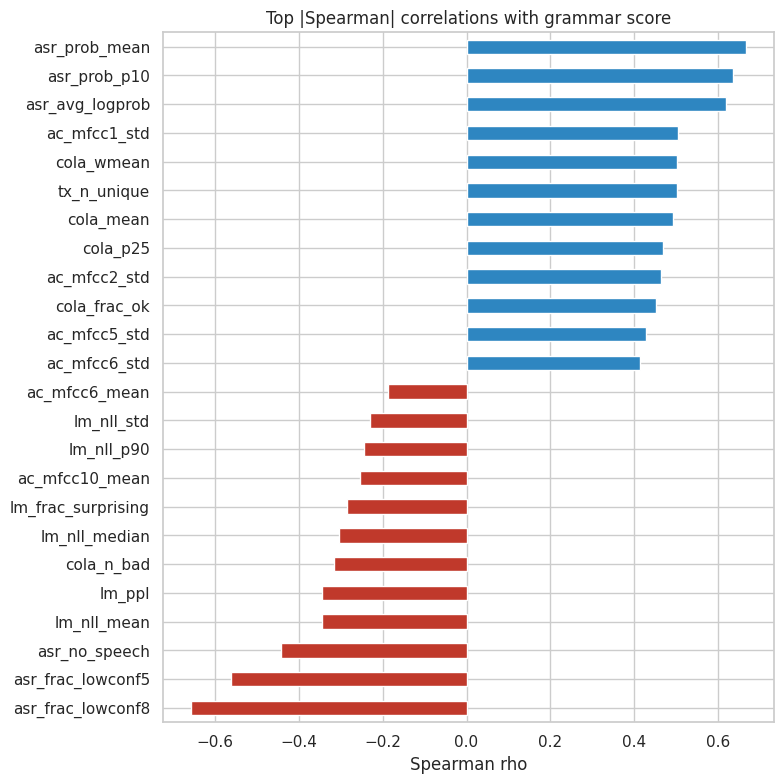

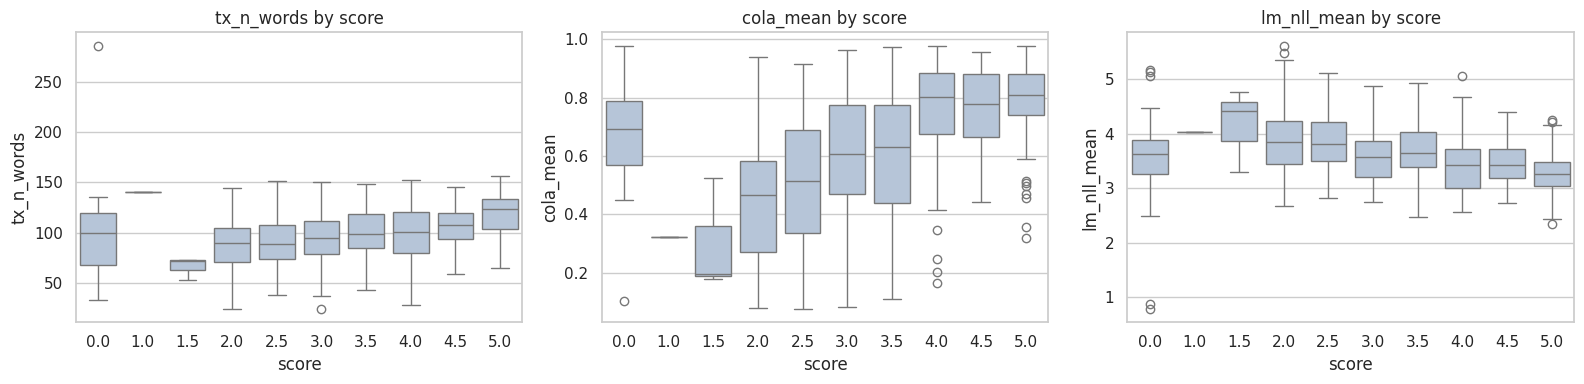

In [21]:
# Which hand-crafted features correlate with the grammar score? (Spearman, train only)
tmp = feat.iloc[:n_tr].copy(); tmp["label"] = y
corr = tmp.corr(method="spearman")["label"].drop("label").dropna().sort_values()
top = pd.concat([corr.head(12), corr.tail(12)])
plt.figure(figsize=(8, 8))
top.plot(kind="barh", color=["#c0392b" if v < 0 else "#2e86c1" for v in top])
plt.title("Top |Spearman| correlations with grammar score"); plt.xlabel("Spearman rho"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, c in zip(ax, ["tx_n_words", "cola_mean", "lm_nll_mean"]):
    sns.boxplot(x=np.round(y * 2) / 2, y=tmp[c], ax=a, color="lightsteelblue"); a.set(title=f"{c} by score", xlabel="score")
plt.tight_layout(); plt.show()

## 6. Modelling

**Validation:** 5-fold CV stratified on score bands (so the rare low-score clips appear in every fold). The same folds are used for every model, so out-of-fold (OOF) predictions are directly comparable and can be stacked.

**Base learners** (diverse on purpose — different feature views and inductive biases):

| Model | Input | Why |
|---|---|---|
| Ridge | hand-crafted | strong, stable linear baseline |
| LightGBM | hand-crafted | non-linear interactions, handles NaN |
| CatBoost | hand-crafted | robust on small tabular data |
| Ridge | transcript embedding | semantic / stylistic signal |
| SVR (RBF) | audio embedding | acoustic / fluency signal |

**Stacking:** a non-negative linear regression on the OOF predictions (weights ≥ 0, so it can't "cancel out" models using unstable negative weights) → clipped to [0, 5].

For each model we report **(a) CV RMSE / Pearson** (honest, out-of-fold) and **(b) training RMSE** (model refit on all 769 samples and evaluated on those same samples — required by the assignment, but optimistic by construction).

In [22]:
def rmse(a, b): return float(np.sqrt(mean_squared_error(a, b)))
def pear(a, b): return float(pearsonr(a, b)[0])

# stratify on score bands (score 1/1.5 are too rare to stratify individually)
bands = np.digitize(y, [1.75, 2.75, 3.75, 4.75])
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(np.zeros(len(y)), bands))

def make_models():
    imp_scale = lambda: [("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]
    return {
        "Ridge | features":  (lambda: Pipeline(imp_scale() + [("m", RidgeCV(alphas=np.logspace(-1, 3, 25)))]), "feat"),
        "LightGBM | features": (lambda: LGBMRegressor(n_estimators=400, learning_rate=0.03, num_leaves=15, min_child_samples=15,
                                  subsample=0.8, subsample_freq=1, colsample_bytree=0.6, reg_lambda=2.0, random_state=SEED, verbose=-1), "feat"),
        "CatBoost | features": (lambda: CatBoostRegressor(iterations=600, depth=5, learning_rate=0.03, l2_leaf_reg=5,
                                  random_seed=SEED, verbose=0), "feat"),
        "Ridge | transcript emb": (lambda: Pipeline([("sc", StandardScaler()), ("m", RidgeCV(alphas=np.logspace(2, 5, 20)))]), "txt"),
        "SVR | audio emb":   (lambda: Pipeline([("sc", StandardScaler()), ("m", SVR(C=3.0, epsilon=0.2, gamma="scale"))]), "aud"),
    }
DATA = {"feat": (X_feat, Xt_feat), "txt": (X_txt, Xt_txt), "aud": (X_aud, Xt_aud)}

results, oof, test_pred, train_pred, fitted = {}, {}, {}, {}, {}
for name, (factory, view) in make_models().items():
    X, Xt = DATA[view]
    o, tp = np.zeros(len(y)), np.zeros(len(Xt))
    for tr, va in folds:
        m = factory().fit(X[tr], y[tr])
        o[va] = m.predict(X[va]); tp += m.predict(Xt) / len(folds)       # test pred = mean of the 5 fold models
    full = factory().fit(X, y)                                           # refit on all data -> training RMSE
    oof[name], test_pred[name], train_pred[name], fitted[name] = np.clip(o, 0, 5), np.clip(tp, 0, 5), np.clip(full.predict(X), 0, 5), full
    results[name] = {"CV RMSE": rmse(y, oof[name]), "CV Pearson": pear(y, oof[name]), "Train RMSE": rmse(y, train_pred[name])}
    print(f"{name:24s} CV RMSE={results[name]['CV RMSE']:.4f}  CV r={results[name]['CV Pearson']:.4f}  train RMSE={results[name]['Train RMSE']:.4f}")

Ridge | features         CV RMSE=0.6444  CV r=0.8545  train RMSE=0.5735
LightGBM | features      CV RMSE=0.6192  CV r=0.8663  train RMSE=0.1065
CatBoost | features      CV RMSE=0.6225  CV r=0.8652  train RMSE=0.2839
Ridge | transcript emb   CV RMSE=1.0289  CV r=0.5564  train RMSE=0.8190
SVR | audio emb          CV RMSE=0.6021  CV r=0.8752  train RMSE=0.2164


In [23]:
# ---------- Stacking ----------
names = list(oof)
O  = np.column_stack([oof[n] for n in names])
T  = np.column_stack([test_pred[n] for n in names])
TR = np.column_stack([train_pred[n] for n in names])

stacker = LinearRegression(positive=True)
# honest estimate of the stacker: cross-validated predictions on the OOF matrix
stack_oof = np.clip(cross_val_predict(LinearRegression(positive=True), O, y, cv=KFold(5, shuffle=True, random_state=SEED + 1)), 0, 5)
stacker.fit(O, y)
stack_train = np.clip(stacker.predict(TR), 0, 5)       # in-sample ("training") predictions
stack_test  = np.clip(stacker.predict(T), 0, 5)        # final test predictions

print("Stacking weights:"); print(pd.Series(stacker.coef_, index=names).round(3).to_string(), "\nintercept:", round(float(stacker.intercept_), 3))
results["STACK (final)"] = {"CV RMSE": rmse(y, stack_oof), "CV Pearson": pear(y, stack_oof), "Train RMSE": rmse(y, stack_train)}
res_df = pd.DataFrame(results).T.sort_values("CV RMSE")
display(res_df.round(4))

Stacking weights:
Ridge | features          0.145
LightGBM | features       0.217
CatBoost | features       0.112
Ridge | transcript emb    0.193
SVR | audio emb           0.578 
intercept: -0.812


,CV RMSE,CV Pearson,Train RMSE
STACK (final),0.5300,0.9040,0.1985
SVR | audio emb,0.6021,0.8752,0.2164
LightGBM | features,0.6192,0.8663,0.1065
CatBoost | features,0.6225,0.8652,0.2839
Ridge | features,0.6444,0.8545,0.5735
Ridge | transcript emb,1.0289,0.5564,0.8190


## 7. Evaluation & visualisations

In [24]:
baseline = rmse(y, np.full_like(y, y.mean()))
final = results["STACK (final)"]
print("=" * 62)
print(f" FINAL MODEL  -  TRAINING RMSE (in-sample, 769 clips): {final['Train RMSE']:.4f}")
print(f"                 CROSS-VALIDATED RMSE (out-of-fold):   {final['CV RMSE']:.4f}")
print(f"                 CROSS-VALIDATED Pearson r:            {final['CV Pearson']:.4f}")
print(f"                 CV Spearman rho / MAE:                {spearmanr(y, stack_oof)[0]:.4f} / {mean_absolute_error(y, stack_oof):.4f}")
print(f" Baseline (always predict the mean) RMSE:              {baseline:.4f}")
print("=" * 62)
print("Within +-0.5 of true score (CV):", round(float((np.abs(y - stack_oof) <= .5).mean()), 3),
      "| within +-1.0:", round(float((np.abs(y - stack_oof) <= 1).mean()), 3))

 FINAL MODEL  -  TRAINING RMSE (in-sample, 769 clips): 0.1985
                 CROSS-VALIDATED RMSE (out-of-fold):   0.5300
                 CROSS-VALIDATED Pearson r:            0.9040
                 CV Spearman rho / MAE:                0.8640 / 0.3974
 Baseline (always predict the mean) RMSE:              1.2382
Within +-0.5 of true score (CV): 0.683 | within +-1.0: 0.935


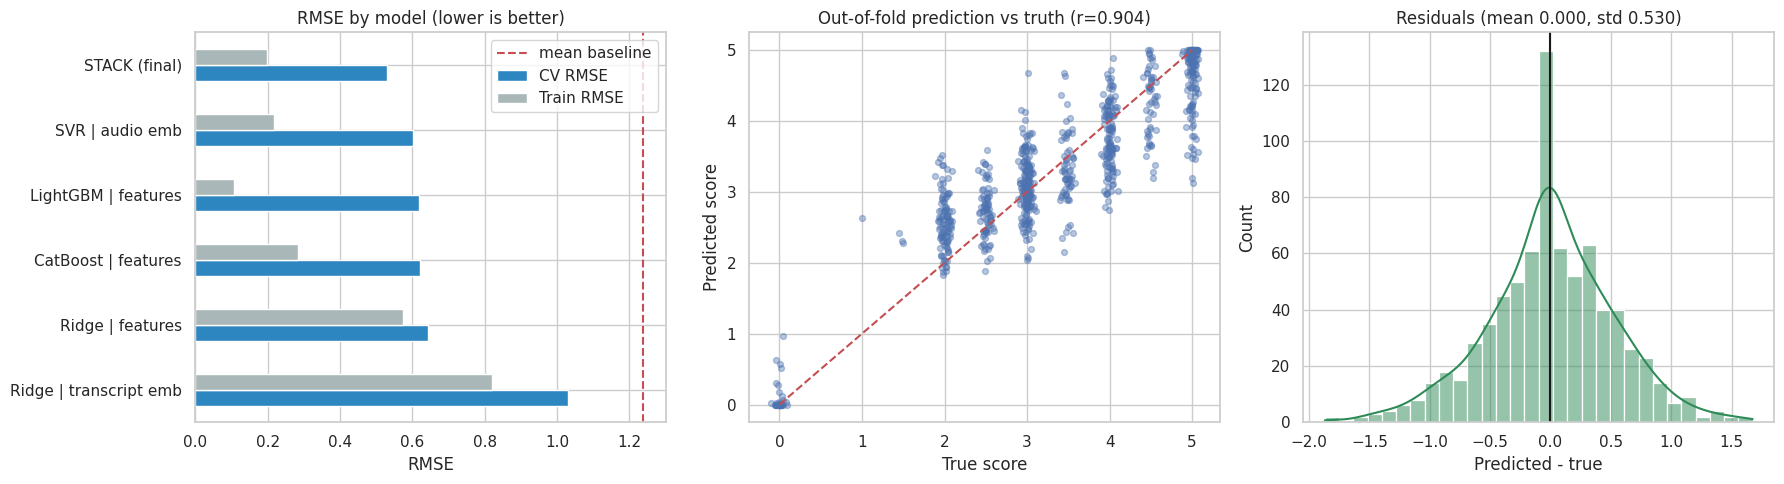

In [25]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# (a) model comparison
r = res_df[["CV RMSE", "Train RMSE"]].iloc[::-1]
r.plot(kind="barh", ax=ax[0], color=["#2e86c1", "#aab7b8"]); ax[0].axvline(baseline, color="r", ls="--", label="mean baseline")
ax[0].set(title="RMSE by model (lower is better)", xlabel="RMSE"); ax[0].legend()

# (b) predicted vs true (OOF)
jit = np.random.RandomState(0).normal(0, .04, len(y))
ax[1].scatter(y + jit, stack_oof, alpha=.4, s=18); ax[1].plot([0, 5], [0, 5], "r--")
ax[1].set(title=f"Out-of-fold prediction vs truth (r={final['CV Pearson']:.3f})", xlabel="True score", ylabel="Predicted score")

# (c) residuals
res = stack_oof - y
sns.histplot(res, bins=30, kde=True, ax=ax[2], color="seagreen"); ax[2].axvline(0, color="k")
ax[2].set(title=f"Residuals (mean {res.mean():.3f}, std {res.std():.3f})", xlabel="Predicted - true")
plt.tight_layout(); plt.show()

,n,rmse,mean_pred
score,,,
0.0,37,0.240,0.101
1.0,1,1.631,2.631
2.0,184,0.599,2.639
3.0,174,0.433,3.093
4.0,240,0.526,3.761
5.0,133,0.588,4.627


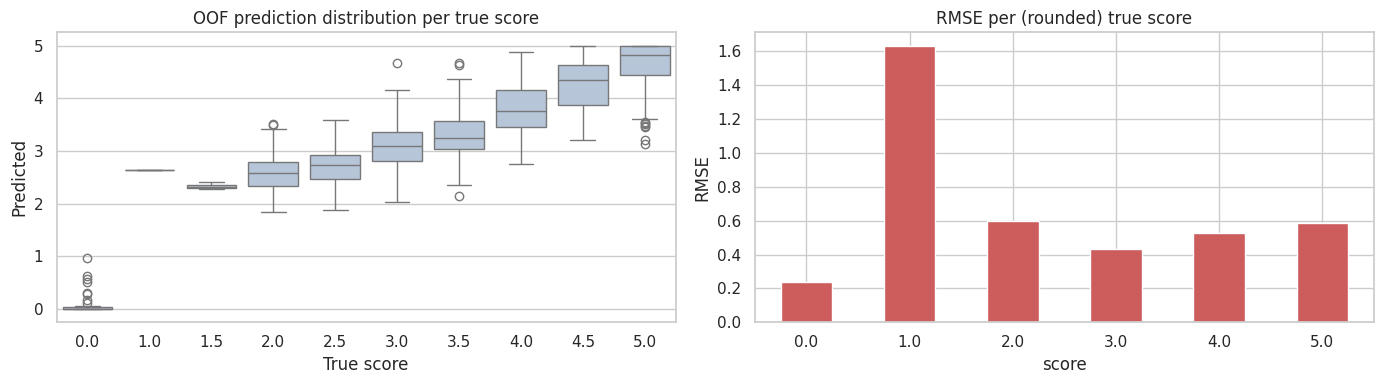

In [26]:
# Error analysis by true score: where does the model struggle?
err = pd.DataFrame({"true": y, "pred": stack_oof}); err["abs_err"] = (err.pred - err.true).abs()
by = err.assign(score=np.round(err.true)).groupby("score").agg(n=("true", "size"), rmse=("abs_err", lambda e: np.sqrt((e ** 2).mean())), mean_pred=("pred", "mean"))
display(by.round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=np.round(err.true * 2) / 2, y=err.pred, ax=ax[0], color="lightsteelblue"); ax[0].set(title="OOF prediction distribution per true score", xlabel="True score", ylabel="Predicted")
by["rmse"].plot(kind="bar", ax=ax[1], color="indianred"); ax[1].set(title="RMSE per (rounded) true score", ylabel="RMSE"); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

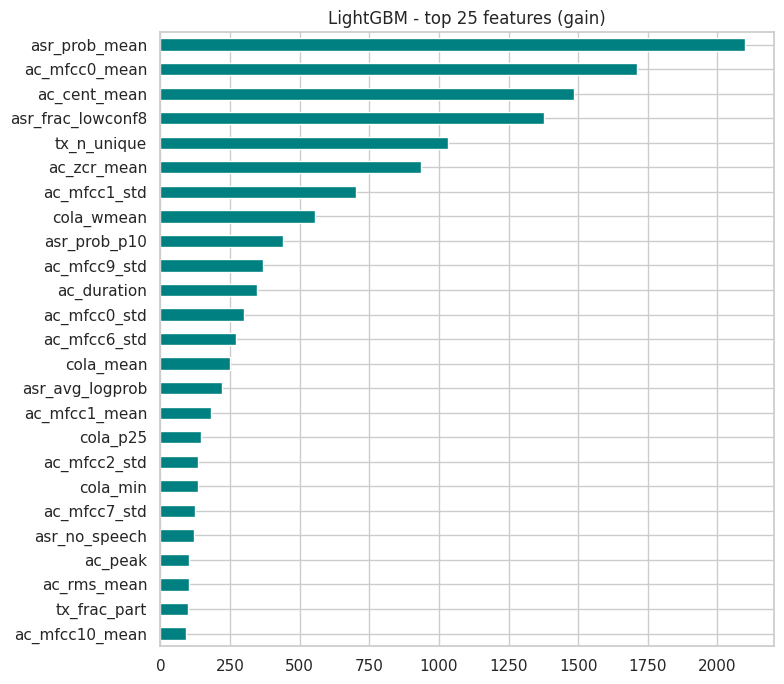

Share of LightGBM gain by feature family  (ac=acoustic, asr=whisper timing/confidence, tx=syntax, lm=GPT-2, cola=acceptability):
ac      0.476
asr     0.278
tx      0.168
cola    0.066
lm      0.013


In [27]:
# Feature importance (LightGBM gain) + the contribution of each feature family
lgb = fitted["LightGBM | features"]
imp = pd.Series(lgb.booster_.feature_importance("gain"), index=feat.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 7)); imp.head(25)[::-1].plot(kind="barh", color="teal")
plt.title("LightGBM - top 25 features (gain)"); plt.tight_layout(); plt.show()

fam = lambda c: c.split("_")[0]
fam_imp = (imp / imp.sum()).groupby(imp.index.map(fam)).sum().sort_values(ascending=False)
print("Share of LightGBM gain by feature family  (ac=acoustic, asr=whisper timing/confidence, tx=syntax, lm=GPT-2, cola=acceptability):")
print(fam_imp.round(3).to_string())

## 8. Test predictions & submission

Submission shape: (216, 2) | columns: ['filename', 'label']


,filename,label
0,audio_128.wav,3.4670
1,audio_156.wav,4.0433
2,audio_19.wav,4.5802
3,audio_108.wav,1.8765
4,audio_206.wav,2.2794
5,audio_161.wav,2.5288
6,audio_215.wav,3.1518
7,audio_213.wav,1.7826
8,audio_11.wav,3.3685
9,audio_155.wav,3.4211


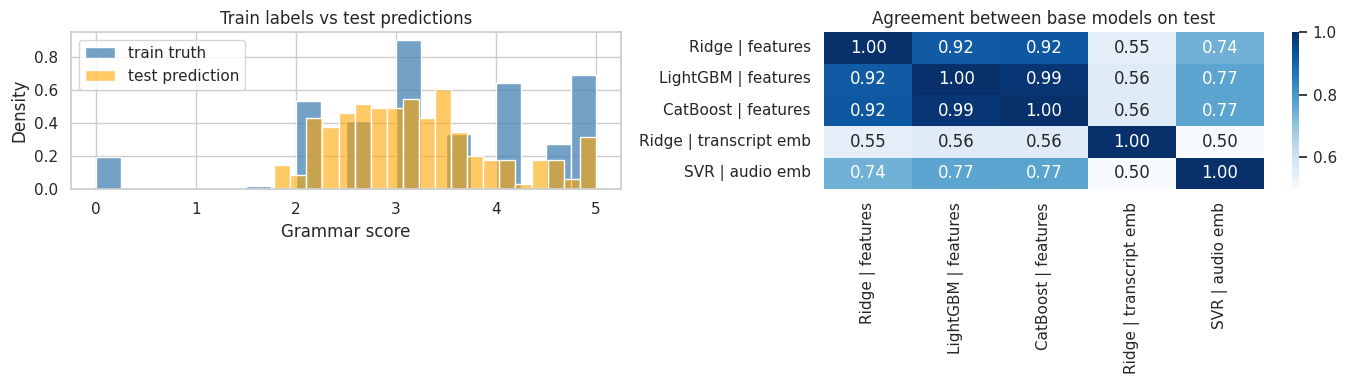


sample_submission: rows = 204 | columns = ['filename', 'label']
Filenames of test.csv found in sample_submission: 25 of 216


In [28]:
submission = pd.DataFrame({"filename": test_df["filename"].values, "label": np.round(stack_test, 4)})
assert len(submission) == len(test_df) and submission["label"].between(0, 5).all() and submission["label"].notna().all()
submission.to_csv("/content/submission_v1.csv", index=False)

print("Submission shape:", submission.shape, "| columns:", submission.columns.tolist())
display(submission.head(10))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(y, bins=20, stat="density", color="steelblue", label="train truth", ax=ax[0]); sns.histplot(stack_test, bins=20, stat="density", color="orange", alpha=.6, label="test prediction", ax=ax[0])
ax[0].set(title="Train labels vs test predictions", xlabel="Grammar score"); ax[0].legend()
corr_m = pd.DataFrame(T, columns=names).corr(); sns.heatmap(corr_m, annot=True, fmt=".2f", cmap="Blues", ax=ax[1]); ax[1].set(title="Agreement between base models on test")
plt.tight_layout(); plt.show()

# Format check against the sample submission
print("\nsample_submission: rows =", len(sample_df), "| columns =", sample_df.columns.tolist())
print("Filenames of test.csv found in sample_submission:", len(set(test_df['filename']) & set(sample_df['filename'])), "of", len(test_df))

# Part B — v2: repeated CV, diagnostics, Whisper encoder, tuned models

| Step | What it does | Why |
|---|---|---|
| 10.1 | Snapshot v1 results, repeated-seed CV helpers | measure improvements reliably (3 x 5-fold instead of 1 x 5-fold) |
| 10.2 | Diagnostics | duration-group error, feature-family ablation, train-vs-test check |
| 10.3 | Whisper-encoder embeddings (all layers) | a stronger "ear" than wav2vec2-base |
| 10.4 | Layer sweep | find which layers carry the grammar/fluency signal |
| 10.5 | Tune SVR + regularise LightGBM | fix overfitting and untuned hyper-parameters |
| 10.6 | Final ensemble, stacking, optional calibration | apples-to-apples v1 vs v2 comparison |
| 10.7 | Write `submission_v2.csv` | only submit if v2 clearly wins in CV |

In [29]:
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.isotonic import IsotonicRegression
from lightgbm import LGBMClassifier

# keep v1 so we can always compare / fall back
stack_test_v1, stack_oof_v1 = stack_test.copy(), stack_oof.copy()
print(f"v1 (single 5-fold split)  CV RMSE = {rmse(y, stack_oof_v1):.4f} | Pearson = {pear(y, stack_oof_v1):.4f}")

# ---- repeated stratified folds: 3 different shuffles of the same 5-fold scheme ----
N_REPEATS = 3
def make_repeated_folds(n_repeats=N_REPEATS, seed=SEED):
    allf = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=n_repeats, random_state=seed).split(np.zeros(len(y)), bands))
    return [allf[i * 5:(i + 1) * 5] for i in range(n_repeats)]       # [repeat][fold] -> (train_idx, val_idx)
rep_folds  = make_repeated_folds()                                    # used for ALL model comparisons
tune_folds = make_repeated_folds(1, seed=SEED + 100)                  # different shuffle, used ONLY for tuning (avoids tuning-on-the-test-folds)

def cv_repeated(factory, X, Xt=None, folds_by_rep=None):
    """Run CV several times. Returns per-repeat OOF predictions, their RMSE mean/std and,
    if Xt is given, test predictions (mean of all fold models) and in-sample training predictions."""
    folds_by_rep = folds_by_rep or rep_folds
    oof_reps, tp, k = [], (np.zeros(len(Xt)) if Xt is not None else None), 0
    for folds in folds_by_rep:
        o = np.zeros(len(y))
        for tr, va in folds:
            m = factory().fit(X[tr], y[tr]); o[va] = m.predict(X[va])
            if Xt is not None: tp += m.predict(Xt); k += 1
        oof_reps.append(np.clip(o, 0, 5))
    r = {"oof_reps": oof_reps, "oof": np.mean(oof_reps, 0),
         "rmse_each": [rmse(y, o) for o in oof_reps], "pearson_each": [pear(y, o) for o in oof_reps]}
    r["rmse_mean"], r["rmse_std"], r["pearson_mean"] = float(np.mean(r["rmse_each"])), float(np.std(r["rmse_each"])), float(np.mean(r["pearson_each"]))
    if Xt is not None:
        r["test"] = np.clip(tp / k, 0, 5)
        r["train"] = np.clip(factory().fit(X, y).predict(X), 0, 5)    # refit on all data -> training RMSE
        r["train_rmse"] = rmse(y, r["train"])
    return r

# ---- model recipes ----
def ridge_feat():  return Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()), ("m", RidgeCV(alphas=np.logspace(-1, 3, 25)))])
def ridge_txt():   return Pipeline([("sc", StandardScaler()), ("m", RidgeCV(alphas=np.logspace(2, 5, 20)))])
def catboost_f():  return CatBoostRegressor(iterations=600, depth=5, learning_rate=0.03, l2_leaf_reg=5, random_seed=SEED, verbose=0)
def lgbm_old():    return LGBMRegressor(n_estimators=400, learning_rate=0.03, num_leaves=15, min_child_samples=15, subsample=0.8, subsample_freq=1,
                                        colsample_bytree=0.6, reg_lambda=2.0, random_state=SEED, verbose=-1)
def lgbm_reg():    return LGBMRegressor(n_estimators=700, learning_rate=0.02, num_leaves=7, max_depth=4, min_child_samples=25, subsample=0.7, subsample_freq=1,
                                        colsample_bytree=0.5, reg_lambda=10.0, reg_alpha=1.0, random_state=SEED, verbose=-1)
def svr_f(C=3.0, eps=0.2, gscale=1.0, d=3072):
    # gamma = gscale / n_features  (with standardised inputs, gscale=1 equals sklearn's gamma='scale')
    return Pipeline([("sc", StandardScaler()), ("m", SVR(C=C, epsilon=eps, gamma=gscale / d))])

VIEWS = {"feat": (X_feat, Xt_feat), "txt": (X_txt, Xt_txt), "aud": (X_aud, Xt_aud)}
RES = {}                                                              # name -> cv_repeated result
def run(name, factory, view):
    X, Xt = VIEWS[view]; r = cv_repeated(factory, X, Xt); RES[name] = r
    print(f"{name:28s} CV RMSE = {r['rmse_mean']:.4f} +- {r['rmse_std']:.4f} | Pearson = {r['pearson_mean']:.4f} | train RMSE = {r['train_rmse']:.4f}")
    return r

v1 (single 5-fold split)  CV RMSE = 0.5300 | Pearson = 0.9040


## 10.2 Diagnostics
Three cheap checks that tell us *what the model is really relying on*:
1. **Error by duration group** - test has many more ~45 s clips than train; is the model weaker there?
2. **Feature-family ablation** - drop acoustic (`ac_`), ASR (`asr_`) or both and see how CV changes. If removing `ac_` barely hurts, the model isn't leaning on microphone/voice cues.
3. **Train-vs-test classifier** - if a model can easily tell train clips from test clips, the two sets differ, and we see in what way.

In [30]:
# ---- 1. error by duration group (v1 out-of-fold predictions) ----
bins, labs = [0, 50, 58, 70], ["<50s (~45s clips)", "50-58s", "~60s"]
d = pd.DataFrame({"grp": pd.cut(train_df["duration"].values, bins, labels=labs), "true": y, "pred": stack_oof_v1})
tbl = d.groupby("grp", observed=True).apply(lambda g: pd.Series({"n_train": len(g), "mean_true": g.true.mean(),
        "RMSE": rmse(g.true, g.pred), "Pearson": pear(g.true, g.pred) if len(g) > 3 else np.nan}))
tbl["n_test"] = pd.cut(test_df["duration"].values, bins, labels=labs).value_counts().reindex(tbl.index).values
display(tbl.round(3))

# ---- 2. feature-family ablation (LightGBM, repeated CV) ----
cols = list(feat.columns)
def subset(drop_prefixes): return [i for i, c in enumerate(cols) if not any(c.startswith(p) for p in drop_prefixes)]
abl = {}
for name, drop in [("all features", []), ("without ac_ (acoustic)", ["ac_"]), ("without asr_ (ASR timing/conf)", ["asr_"]),
                   ("without ac_ and asr_ (text-only)", ["ac_", "asr_"])]:
    idx = subset(drop); r = cv_repeated(lgbm_old, X_feat[:, idx])
    abl[name] = (len(idx), r["rmse_mean"], r["rmse_std"], r["pearson_mean"]); print(f"{name:34s} n_feat={len(idx):3d}  RMSE={r['rmse_mean']:.4f} +- {r['rmse_std']:.4f}")
display(pd.DataFrame(abl, index=["n_features", "CV RMSE", "std", "Pearson"]).T.round(4))

# ---- 3. adversarial validation: can a model tell train from test? ----
is_test = np.r_[np.zeros(n_tr), np.ones(len(all_df) - n_tr)]
Xall = feat.values
clf = lambda: LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=15, verbose=-1, random_state=SEED)
p = cross_val_predict(clf(), Xall, is_test, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
adv_auc = roc_auc_score(is_test, p)
print(f"\nTrain-vs-test AUC = {adv_auc:.3f}   (0.5 = indistinguishable, 1.0 = trivially different)")
imp_adv = pd.Series(clf().fit(Xall, is_test).booster_.feature_importance("gain"), index=cols).sort_values(ascending=False)
print("Features that give the difference away:\n", imp_adv.head(8).round(0).to_string())

,n_train,mean_true,RMSE,Pearson,n_test
grp,,,,,
<50s (~45s clips),182.0,3.063,0.622,0.782,149
50-58s,27.0,3.759,0.568,0.859,8
~60s,560.0,3.373,0.494,0.926,59


all features                       n_feat=137  RMSE=0.6256 +- 0.0051
without ac_ (acoustic)             n_feat= 97  RMSE=0.7742 +- 0.0059
without asr_ (ASR timing/conf)     n_feat=117  RMSE=0.6749 +- 0.0075
without ac_ and asr_ (text-only)   n_feat= 77  RMSE=1.0515 +- 0.0093


,n_features,CV RMSE,std,Pearson
all features,137.0,0.6256,0.0051,0.8633
without ac_ (acoustic),97.0,0.7742,0.0059,0.7809
without asr_ (ASR timing/conf),117.0,0.6749,0.0075,0.8385
without ac_ and asr_ (text-only),77.0,1.0515,0.0093,0.5382



Train-vs-test AUC = 0.827   (0.5 = indistinguishable, 1.0 = trivially different)
Features that give the difference away:
 ac_duration       1644.0
tx_pos_PROPN       348.0
tx_pos_CCONJ       214.0
ac_mfcc3_mean      206.0
ac_mfcc12_mean     205.0
ac_mfcc4_mean      197.0
ac_mfcc12_std      186.0
lm_nll_std         161.0


**How to read 10.2**
* If the `<50s` group has clearly higher RMSE than the others, that's where the test set will hurt, and the later steps should target it.
* If "text-only" CV is close to "all features", the model is mostly using grammar-relevant signal. If it is much worse, much of the performance comes from voice/recording cues.
* A high train-vs-test AUC driven by `ac_duration` just reflects the different mix of 45 s / 60 s clips we already saw; high AUC driven by MFCC/spectral features would suggest different recording conditions.

## 10.3 Whisper-encoder embeddings (every layer)
Whisper's encoder was trained on a huge amount of multilingual speech, so its internal representation captures pronunciation, fluency and language knowledge. We keep the **time-averaged output of all 13 layers** (input embedding + 12 transformer layers), so the next step can find which layers work best.
* Whisper's encoder takes exactly 30 s windows, so a ~60 s clip is cut into 30 s chunks and the per-chunk averages are combined weighted by the amount of real audio.
* Padding (silence added to fill a short chunk) is ignored when averaging.

In [31]:
from transformers import WhisperFeatureExtractor, WhisperModel

WH_ENC = "openai/whisper-small.en"                 # 12 layers x 768-d. ("openai/whisper-medium.en" is stronger but 3x slower)
WENC_FILE = f"{WORK}/whisper_enc_layers_{WH_ENC.split('/')[-1]}.npy"

if os.path.exists(WENC_FILE):
    wenc = np.load(WENC_FILE)
else:
    wfe = WhisperFeatureExtractor.from_pretrained(WH_ENC)
    enc = WhisperModel.from_pretrained(WH_ENC).encoder.to(DEVICE).eval()
    if DEVICE == "cuda": enc = enc.half()
    CH, out = 30 * SR, []
    for pth in tqdm(all_df["path"], desc="Whisper encoder"):
        wav, _ = librosa.load(pth, sr=SR, mono=True)
        chunks = [wav[i:i + CH] for i in range(0, max(len(wav), 1), CH)]
        chunks = [c for c in chunks if len(c) >= SR] or [wav if len(wav) else np.zeros(SR, dtype=np.float32)]   # drop tiny tail chunks
        acc, wsum = None, 0
        for c in chunks:
            x = wfe(c, sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE)      # padded to 30 s
            if DEVICE == "cuda": x = x.half()
            with torch.no_grad(): hs = enc(x, output_hidden_states=True).hidden_states       # 13 x (1, 1500, 768)
            n_valid = max(1, int(len(c) / SR * 50))                                           # encoder runs at 50 frames/s
            v = torch.stack([h[0, :n_valid].float().mean(0) for h in hs])                    # (13, 768), padding ignored
            acc = v * n_valid if acc is None else acc + v * n_valid; wsum += n_valid
        out.append((acc / wsum).cpu().numpy())
    wenc = np.stack(out); np.save(WENC_FILE, wenc)
    del enc; gc.collect(); torch.cuda.empty_cache()
print("Whisper encoder embeddings:", wenc.shape, "(clips, layers, dims)")

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.94k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  967MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

Whisper encoder:   0%|          | 0/985 [00:00<?, ?it/s]

Whisper encoder embeddings: (985, 13, 768) (clips, layers, dims)


## 10.4 Layer sweep
Each layer of a deep model captures a different kind of information (early = raw sound, middle = speech sounds / fluency, late = more abstract). We fit the same SVR on each layer separately and plot the CV error, then keep the best few layers.

layer  0: RMSE=0.7457  r=0.7983
layer  1: RMSE=0.6383  r=0.8585
layer  2: RMSE=0.6139  r=0.8725
layer  3: RMSE=0.6075  r=0.8760
layer  4: RMSE=0.5813  r=0.8877
layer  5: RMSE=0.5745  r=0.8905
layer  6: RMSE=0.5655  r=0.8948
layer  7: RMSE=0.5536  r=0.9008
layer  8: RMSE=0.5556  r=0.8992
layer  9: RMSE=0.5629  r=0.8960
layer 10: RMSE=0.5673  r=0.8943
layer 11: RMSE=0.5631  r=0.8961
layer 12: RMSE=0.5655  r=0.8952


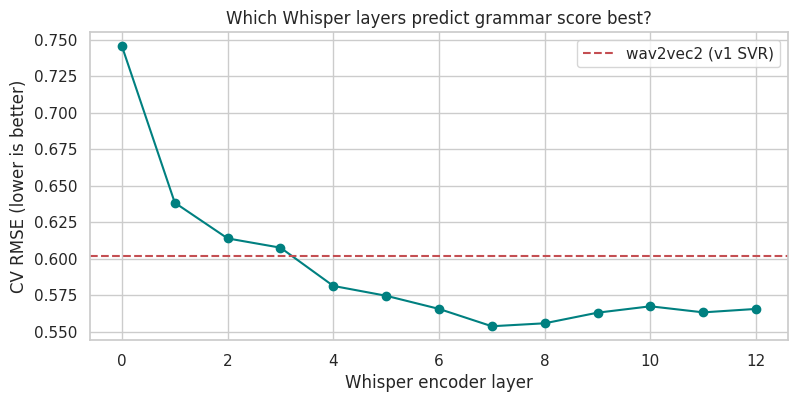

Best layers: [7, 8, 9]
Whisper-encoder feature matrix: (769, 2304)


In [32]:
sweep = []
for L in range(wenc.shape[1]):
    r = cv_repeated(lambda: svr_f(d=wenc.shape[2]), wenc[:n_tr, L], folds_by_rep=rep_folds[:1])     # 1 repeat for speed
    sweep.append((L, r["rmse_mean"], r["pearson_mean"])); print(f"layer {L:2d}: RMSE={r['rmse_mean']:.4f}  r={r['pearson_mean']:.4f}")
sweep = pd.DataFrame(sweep, columns=["layer", "rmse", "pearson"])

plt.figure(figsize=(9, 4)); plt.plot(sweep.layer, sweep.rmse, "o-", color="teal")
RES_aud = cv_repeated(lambda: svr_f(d=X_aud.shape[1]), X_aud, folds_by_rep=rep_folds[:1])["rmse_mean"]
plt.axhline(RES_aud, color="r", ls="--", label="wav2vec2 (v1 SVR)")
plt.xlabel("Whisper encoder layer"); plt.ylabel("CV RMSE (lower is better)"); plt.title("Which Whisper layers predict grammar score best?"); plt.legend(); plt.show()

TOP_LAYERS = sweep.sort_values("rmse").layer.head(3).tolist()          # NB: choosing layers on CV is mildly optimistic (only 13 options)
print("Best layers:", TOP_LAYERS)
X_wenc  = np.concatenate([wenc[:n_tr, L] for L in TOP_LAYERS], axis=1)
Xt_wenc = np.concatenate([wenc[n_tr:, L] for L in TOP_LAYERS], axis=1)
VIEWS["wenc"] = (X_wenc, Xt_wenc); print("Whisper-encoder feature matrix:", X_wenc.shape)

## 10.5 Tuning SVR and regularising LightGBM
* **SVR** had untuned `C` (how strictly it fits), `epsilon` (error it ignores) and `gamma` (how local its curve is). We grid-search them using a *different* fold shuffle (`tune_folds`) from the one used for final comparison, so the comparison isn't flattered by tuning on the same splits.
* **LightGBM** memorised the training set (train RMSE 0.11 vs CV 0.62), so we try a more cautious version: shallower trees, bigger leaves, stronger penalties.

In [33]:
import itertools
def tune_svr(X, name):
    d, rows = X.shape[1], []
    for C, eps, g in itertools.product([1, 3, 10, 30], [0.1, 0.2, 0.4], [0.3, 1, 3]):
        r = cv_repeated(lambda: svr_f(C, eps, g, d), X, folds_by_rep=tune_folds)
        rows.append({"C": C, "eps": eps, "gscale": g, "rmse": r["rmse_mean"]})
    t = pd.DataFrame(rows).sort_values("rmse"); print(f"\n{name}: top 5 settings"); display(t.head(5).round(4)); return t.iloc[0]

best_w2v  = tune_svr(X_aud,  "SVR on wav2vec2 embedding")
best_wenc = tune_svr(X_wenc, "SVR on Whisper-encoder embedding")


SVR on wav2vec2 embedding: top 5 settings


,C,eps,gscale,rmse
10,3,0.1,1.0,0.5885
19,10,0.1,1.0,0.5897
28,30,0.1,1.0,0.5899
18,10,0.1,0.3,0.5902
21,10,0.2,0.3,0.5914



SVR on Whisper-encoder embedding: top 5 settings


,C,eps,gscale,rmse
18,10,0.1,0.3,0.5397
27,30,0.1,0.3,0.5402
30,30,0.2,0.3,0.5409
9,3,0.1,0.3,0.5412
21,10,0.2,0.3,0.5415


In [34]:
print("=== Candidates evaluated on the SAME repeated folds ===")
run("Ridge | features",         ridge_feat, "feat")
run("LightGBM (old)",            lgbm_old,   "feat")
run("LightGBM (regularised)",    lgbm_reg,   "feat")
run("CatBoost | features",       catboost_f, "feat")
run("Ridge | transcript emb",    ridge_txt,  "txt")
run("SVR | wav2vec2 (old)",      lambda: svr_f(3.0, 0.2, 1.0, X_aud.shape[1]), "aud")
run("SVR | wav2vec2 (tuned)",    lambda: svr_f(best_w2v.C, best_w2v.eps, best_w2v.gscale, X_aud.shape[1]), "aud")
run("SVR | whisper enc (tuned)", lambda: svr_f(best_wenc.C, best_wenc.eps, best_wenc.gscale, X_wenc.shape[1]), "wenc")

=== Candidates evaluated on the SAME repeated folds ===
Ridge | features             CV RMSE = 0.6471 +- 0.0021 | Pearson = 0.8530 | train RMSE = 0.5735
LightGBM (old)               CV RMSE = 0.6256 +- 0.0051 | Pearson = 0.8633 | train RMSE = 0.1065
LightGBM (regularised)       CV RMSE = 0.6292 +- 0.0091 | Pearson = 0.8614 | train RMSE = 0.3106
CatBoost | features          CV RMSE = 0.6300 +- 0.0054 | Pearson = 0.8616 | train RMSE = 0.2839
Ridge | transcript emb       CV RMSE = 1.0228 +- 0.0044 | Pearson = 0.5636 | train RMSE = 0.8190
SVR | wav2vec2 (old)         CV RMSE = 0.5898 +- 0.0088 | Pearson = 0.8810 | train RMSE = 0.2164
SVR | wav2vec2 (tuned)       CV RMSE = 0.5835 +- 0.0090 | Pearson = 0.8827 | train RMSE = 0.1706
SVR | whisper enc (tuned)    CV RMSE = 0.5358 +- 0.0032 | Pearson = 0.9017 | train RMSE = 0.1078


{'oof_reps': [array([3.44696595, 2.71230576, 3.16191098, 2.78749239, 2.21677176,
         2.5303683 , 2.84738735, 3.38836758, 3.74217057, 3.27840209,
         4.537058  , 3.00586556, 2.29000836, 3.40874212, 2.10646246,
         2.17316966, 4.0084925 , 0.01047639, 2.0503993 , 4.0981591 ,
         3.31182014, 3.0078327 , 4.29098199, 2.56501867, 3.2305774 ,
         4.14307566, 3.18014541, 3.80549319, 2.78014084, 3.74627307,
         0.        , 3.59913872, 3.19155795, 2.22908935, 2.56521116,
         2.59104004, 5.        , 3.49681128, 3.30517194, 3.91126956,
         2.84968281, 0.12855876, 4.16950407, 3.30161287, 2.98687999,
         4.33690186, 2.36693579, 1.9898095 , 2.50245098, 0.15195232,
         4.16687224, 1.02715472, 2.9797529 , 3.11067506, 2.25961618,
         4.56900183, 4.44530182, 2.95943378, 3.65033526, 4.42653411,
         3.0551069 , 1.72936304, 2.55253913, 3.31223689, 3.9200782 ,
         4.92271996, 5.        , 5.        , 2.33987353, 5.        ,
         4.07445897, 4

## 10.6 Final ensemble: stacking (+ optional calibration)
* **v1-equivalent** = the original five models, now scored on the repeated folds, so the comparison is fair.
* **v2** = adds the Whisper-encoder model, swaps in the tuned SVR and the regularised LightGBM.
* **Calibration** (isotonic regression) learns a monotone curve mapping the stacked output to the true scale. It can fix the squeeze toward the middle (2s predicted too high, 5s too low). We keep it only if it lowers CV error.

In [35]:
def stack_cv_eval(names, use_iso=False):
    """Honest per-repeat score of 'stack (+ calibrate)': both layers are evaluated out-of-fold."""
    sc = []
    for r in range(N_REPEATS):
        Or = np.column_stack([RES[n]["oof_reps"][r] for n in names])
        s = np.clip(cross_val_predict(LinearRegression(positive=True), Or, y, cv=KFold(5, shuffle=True, random_state=SEED + r)), 0, 5)
        if use_iso:
            c = np.zeros_like(s)
            for tr, va in KFold(5, shuffle=True, random_state=SEED + 50 + r).split(s):
                c[va] = IsotonicRegression(out_of_bounds="clip").fit(s[tr], y[tr]).predict(s[va])
            s = np.clip(c, 0, 5)
        sc.append((rmse(y, s), pear(y, s)))
    return np.array(sc)

V1 = ["Ridge | features", "LightGBM (old)", "CatBoost | features", "Ridge | transcript emb", "SVR | wav2vec2 (old)"]
V2 = ["Ridge | features", "LightGBM (regularised)", "CatBoost | features", "Ridge | transcript emb", "SVR | wav2vec2 (tuned)", "SVR | whisper enc (tuned)"]

rows = {}
for label, names, iso in [("v1-equivalent (5 models)", V1, False), ("v2 stack", V2, False), ("v2 stack + isotonic calibration", V2, True)]:
    s = stack_cv_eval(names, iso); rows[label] = {"CV RMSE": s[:, 0].mean(), "RMSE std": s[:, 0].std(), "CV Pearson": s[:, 1].mean()}
cmp_df = pd.DataFrame(rows).T; display(cmp_df.round(4))

USE_ISO = cmp_df.loc["v2 stack + isotonic calibration", "CV RMSE"] < cmp_df.loc["v2 stack", "CV RMSE"] - 0.003    # require a real gain
print("Use isotonic calibration:", USE_ISO)

,CV RMSE,RMSE std,CV Pearson
v1-equivalent (5 models),0.5268,0.0018,0.9052
v2 stack,0.4962,0.0023,0.9164
v2 stack + isotonic calibration,0.4969,0.0023,0.9160


Use isotonic calibration: False


In [36]:
# ---- fit the final v2 stacker on the (repeat-averaged) OOF predictions ----
O2  = np.column_stack([RES[n]["oof"]   for n in V2])
T2  = np.column_stack([RES[n]["test"]  for n in V2])
TR2 = np.column_stack([RES[n]["train"] for n in V2])

stacker2 = LinearRegression(positive=True).fit(O2, y)
s_oof = np.clip(cross_val_predict(LinearRegression(positive=True), O2, y, cv=KFold(5, shuffle=True, random_state=SEED + 1)), 0, 5)
print("Stacking weights:"); print(pd.Series(stacker2.coef_, index=V2).round(3).to_string(), "| intercept:", round(float(stacker2.intercept_), 3))

if USE_ISO:
    iso = IsotonicRegression(out_of_bounds="clip").fit(s_oof, y)
    post = lambda s: np.clip(iso.predict(s), 0, 5)
else:
    post = lambda s: np.clip(s, 0, 5)

v2_oof   = post(s_oof)
v2_train = post(stacker2.predict(TR2))                    # in-sample ("training") predictions
v2_test  = post(stacker2.predict(T2))                     # final test predictions

hdr = cmp_df.loc["v2 stack + isotonic calibration" if USE_ISO else "v2 stack"]
print("=" * 64)
print(f" v2 TRAINING RMSE (in-sample, required):      {rmse(y, v2_train):.4f}")
print(f" v2 CV RMSE (3 x 5-fold, per-repeat mean):    {hdr['CV RMSE']:.4f} +- {hdr['RMSE std']:.4f}")
print(f" v2 CV Pearson:                               {hdr['CV Pearson']:.4f}")
print(f" v1 CV RMSE, same folds (fair comparison):    {cmp_df.loc['v1-equivalent (5 models)', 'CV RMSE']:.4f}")
print("=" * 64)

Stacking weights:
Ridge | features             0.104
LightGBM (regularised)       0.041
CatBoost | features          0.114
Ridge | transcript emb       0.131
SVR | wav2vec2 (tuned)       0.265
SVR | whisper enc (tuned)    0.528 | intercept: -0.606
 v2 TRAINING RMSE (in-sample, required):      0.1525
 v2 CV RMSE (3 x 5-fold, per-repeat mean):    0.4962 +- 0.0023
 v2 CV Pearson:                               0.9164
 v1 CV RMSE, same folds (fair comparison):    0.5268


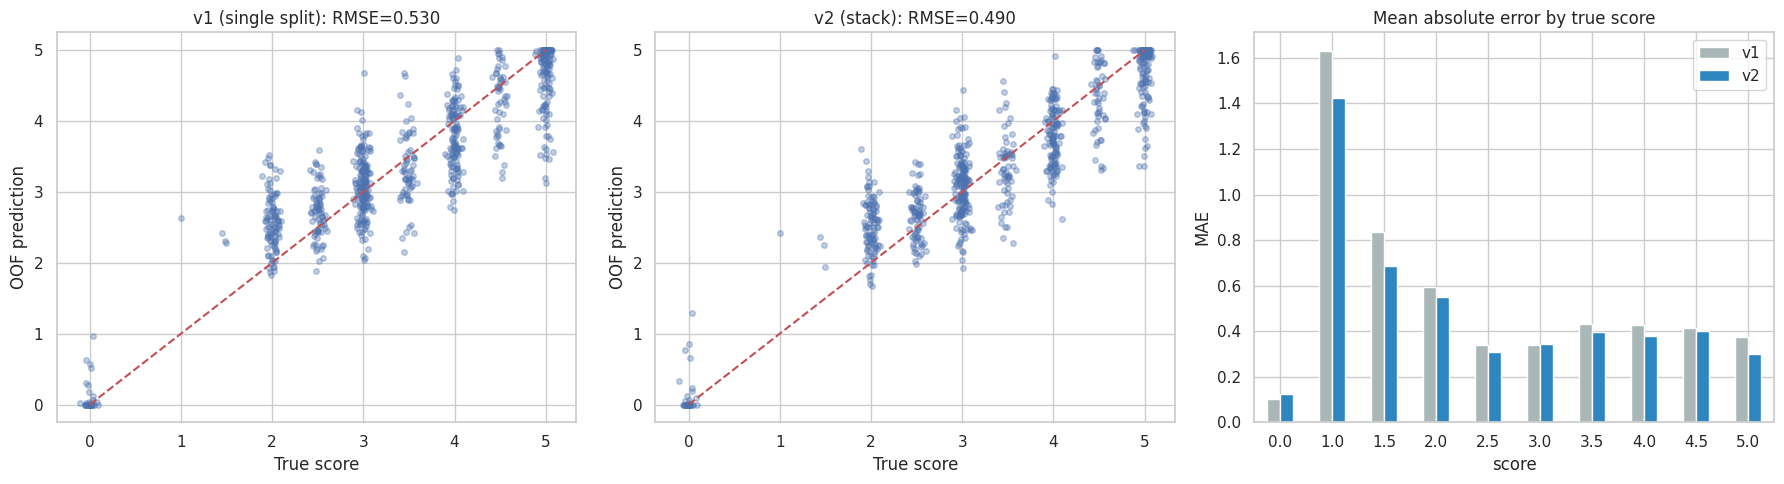

In [37]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
jit = np.random.RandomState(0).normal(0, .04, len(y))
for a, (t, p_) in zip(ax[:2], [("v1 (single split)", stack_oof_v1), ("v2 (stack" + (" + isotonic" if USE_ISO else "") + ")", v2_oof)]):
    a.scatter(y + jit, p_, alpha=.35, s=16); a.plot([0, 5], [0, 5], "r--"); a.set(title=f"{t}: RMSE={rmse(y, p_):.3f}", xlabel="True score", ylabel="OOF prediction")
by = pd.DataFrame({"score": np.round(y * 2) / 2, "v1": np.abs(stack_oof_v1 - y), "v2": np.abs(v2_oof - y)}).groupby("score").mean()
by.plot(kind="bar", ax=ax[2], color=["#aab7b8", "#2e86c1"]); ax[2].set(title="Mean absolute error by true score", ylabel="MAE"); ax[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

## 10.7 Submission v2
Only upload this if 10.6 shows v2 beating the v1-equivalent by clearly more than its `RMSE std`. The public leaderboard is only a sample of the test set, so don't pick between v1 and v2 on public-score differences of a few hundredths.

v1 vs v2 test-prediction correlation: 0.9739 | mean abs difference: 0.1471


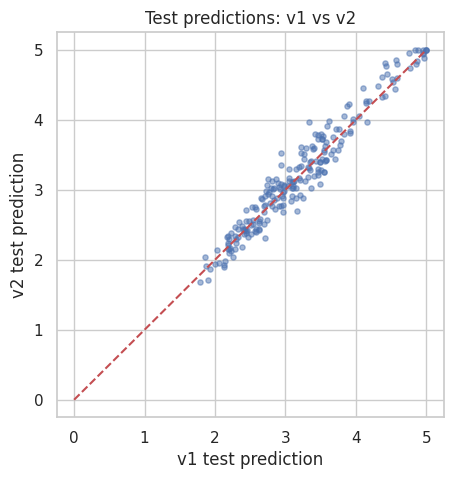

,filename,label
0,audio_128.wav,3.2526
1,audio_156.wav,4.0578
2,audio_19.wav,4.5940
3,audio_108.wav,1.9173
4,audio_206.wav,2.1482


In [38]:
sub2 = pd.DataFrame({"filename": test_df["filename"].values, "label": np.round(v2_test, 4)})
assert len(sub2) == len(test_df) and sub2["label"].between(0, 5).all() and sub2["label"].notna().all()
sub2.to_csv("/content/submission_v2.csv", index=False)

print("v1 vs v2 test-prediction correlation:", round(pear(stack_test_v1, v2_test), 4), "| mean abs difference:", round(float(np.abs(stack_test_v1 - v2_test).mean()), 4))
plt.figure(figsize=(5, 5)); plt.scatter(stack_test_v1, v2_test, alpha=.5, s=14); plt.plot([0, 5], [0, 5], "r--")
plt.xlabel("v1 test prediction"); plt.ylabel("v2 test prediction"); plt.title("Test predictions: v1 vs v2"); plt.show()
display(sub2.head())

# Part C — v3: duration-aware validation and test-mix weighting

**Why these steps (in priority order of expected gain)**

| Step | Change | Why it should help |
|---|---|---|
| 11.1 | Duration-aware folds + a *test-mix weighted* RMSE | 69% of test clips are ~45 s but only 24% of train clips are. Your CV was dominated by 60 s clips, which are the easy ones (RMSE 0.50 vs 0.63 for short clips). Without this, you can't tell which changes help on the data that matters. |
| 11.2 | Count features per minute | `ac_n_segments`, `asr_n_gap_*`, `tx_n_*` etc. are raw counts: they scale with clip length, so the model learns "short clip => few pauses => X" which is a *length* effect, not a grammar effect. Converting to rates removes that confound. |
| 11.3 | Whisper layers 5-12 averaged + scaling fitted on train+test | Your layer sweep was flat from layer 5 to 12: the signal is spread out, so averaging is less noisy than 3 hand-picked layers (also removes the mild selection bias of picking the top 3 on CV). Standardising with test statistics (unsupervised, no labels) lets the kernel see test clips on the same scale. |
| 11.4 | One SVR on [Whisper embedding + hand-crafted features] | Ablation showed acoustic/ASR features are very informative, but they only meet the embedding in the stacker. A joint kernel lets the model use interactions between "what the encoder hears" and "pause/rate statistics". |
| 11.5 | Extra diverse stack members | Stacking gains come from *decorrelated* errors. Adds SVRs on single layers and kernel ridge. |
| 11.6 | Duration-aware stacker | Short clips have a lower mean score (3.06 vs 3.37). The stacker gets group-specific offsets so it can correct a systematic bias per group. |
| 11.7 | Compare v2 vs v3 and write `submission_v3.csv` | Only if v3 wins on the test-mix weighted CV. |

## 11.1 Duration-aware validation and a test-mix weighted metric

In [39]:
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.kernel_ridge import KernelRidge
import itertools

# ---- duration groups: "short" = the ~45 s clips that dominate the test set ----
dur_all = all_df["duration"].values.astype(float)
dur_tr, dur_te = dur_all[:n_tr], dur_all[n_tr:]
short_tr, short_te = (dur_tr < 50).astype(int), (dur_te < 50).astype(int)

# importance weights: make the train mix look like the test mix
w_short = short_te.mean() / short_tr.mean()
w_long  = (1 - short_te.mean()) / (1 - short_tr.mean())
w_tr = np.where(short_tr == 1, w_short, w_long)
print(f"short clips: train {short_tr.mean():.1%} vs test {short_te.mean():.1%}  ->  weights short={w_short:.2f}, long={w_long:.2f}")

# ---- folds stratified on score band x duration group (tiny strata are merged so every fold is valid) ----
strata = bands * 2 + short_tr
cnt = pd.Series(strata).value_counts()
strata = np.where(pd.Series(strata).map(cnt).values < 10, 100 + short_tr, strata)

def make_folds(n_rep, seed):
    allf = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=n_rep, random_state=seed).split(np.zeros(len(y)), strata))
    return [allf[i * 5:(i + 1) * 5] for i in range(n_rep)]
REP3, TUNE3 = make_folds(N_REPEATS, SEED + 7), make_folds(1, SEED + 107)     # TUNE3 is used only for tuning

# ---- metrics: plain RMSE, test-mix weighted RMSE, per-group RMSE, Pearson ----
def summarize(p):
    s, l = short_tr == 1, short_tr == 0
    return {"RMSE": rmse(y, p), "wRMSE": float(np.sqrt(np.sum(w_tr * (y - p) ** 2) / w_tr.sum())),
            "RMSE short": rmse(y[s], p[s]), "RMSE long": rmse(y[l], p[l]), "Pearson": pear(y, p)}
mean_summary = lambda reps: pd.DataFrame([summarize(o) for o in reps]).mean().to_dict()

RES3 = {}
def run3(name, factory, X, Xt):
    r = cv_repeated(factory, X, Xt, folds_by_rep=REP3); r["sum"] = mean_summary(r["oof_reps"]); RES3[name] = r
    s = r["sum"]; print(f"{name:30s} wRMSE={s['wRMSE']:.4f} | RMSE={s['RMSE']:.4f} (short {s['RMSE short']:.3f} / long {s['RMSE long']:.3f}) | r={s['Pearson']:.4f} | train RMSE={r['train_rmse']:.4f}")
    return r

def tune3(make, X, grid, name):
    """Grid search on the separate TUNE3 folds, scored by the test-mix weighted RMSE."""
    rows = []
    for vals in itertools.product(*grid.values()):
        p = dict(zip(grid, vals)); r = cv_repeated(lambda: make(**p), X, folds_by_rep=TUNE3)
        rows.append({**p, "wRMSE": mean_summary(r["oof_reps"])["wRMSE"]})
    t = pd.DataFrame(rows).sort_values("wRMSE"); print(f"\n{name}: top 3"); display(t.head(3).round(4))
    return {k: t.iloc[0][k] for k in grid}

# ---- stacking helpers (optionally with duration-group offsets, see 11.6) ----
def design(P, short, use_dur):
    if not use_dur: return P
    s = short.reshape(-1, 1).astype(float)
    return np.hstack([P, s, -s, 1 - s, -(1 - s)])           # +/- columns let the (non-negative) stacker learn signed group offsets
stacker = lambda use_dur: LinearRegression(positive=True, fit_intercept=not use_dur)

def stack_eval(names, use_dur=False):
    out = []
    for r in range(N_REPEATS):
        P = np.column_stack([RES3[n]["oof_reps"][r] for n in names])
        s = np.clip(cross_val_predict(stacker(use_dur), design(P, short_tr, use_dur), y, cv=KFold(5, shuffle=True, random_state=SEED + r)), 0, 5)
        out.append(summarize(s))
    return pd.DataFrame(out).mean().to_dict()

def stack_final(names, use_dur=False):
    O, T, TR = [np.column_stack([RES3[n][k] for n in names]) for k in ("oof", "test", "train")]
    m = stacker(use_dur).fit(design(O, short_tr, use_dur), y)
    return m, np.clip(m.predict(design(T, short_te, use_dur)), 0, 5), np.clip(m.predict(design(TR, short_tr, use_dur)), 0, 5)

# ---- baseline: the v2 members re-scored on the new folds ----
BASE = {
    "Ridge | feat":               (ridge_feat, X_feat, Xt_feat),
    "LGBM reg | feat":            (lgbm_reg, X_feat, Xt_feat),
    "CatBoost | feat":            (catboost_f, X_feat, Xt_feat),
    "Ridge | txt":                (ridge_txt, X_txt, Xt_txt),
    "SVR | w2v (tuned)":          (lambda: svr_f(best_w2v.C, best_w2v.eps, best_w2v.gscale, X_aud.shape[1]), X_aud, Xt_aud),
    "SVR | whisper L7-9 (tuned)": (lambda: svr_f(best_wenc.C, best_wenc.eps, best_wenc.gscale, X_wenc.shape[1]), X_wenc, Xt_wenc),
}
for n, (f, X, Xt) in BASE.items(): run3(n, f, X, Xt)
V2N = list(BASE)
print("\nv2 stack on the new folds:", {k: round(v, 4) for k, v in stack_eval(V2N).items()})

short clips: train 23.7% vs test 69.0%  ->  weights short=2.91, long=0.41
Ridge | feat                   wRMSE=0.6674 | RMSE=0.6466 (short 0.681 / long 0.635) | r=0.8533 | train RMSE=0.5735
LGBM reg | feat                wRMSE=0.6681 | RMSE=0.6315 (short 0.692 / long 0.611) | r=0.8603 | train RMSE=0.3106
CatBoost | feat                wRMSE=0.6673 | RMSE=0.6327 (short 0.690 / long 0.614) | r=0.8602 | train RMSE=0.2839
Ridge | txt                    wRMSE=0.9274 | RMSE=1.0152 (short 0.862 / long 1.058) | r=0.5724 | train RMSE=0.8190
SVR | w2v (tuned)              wRMSE=0.6600 | RMSE=0.5733 (short 0.713 / long 0.522) | r=0.8872 | train RMSE=0.1706
SVR | whisper L7-9 (tuned)     wRMSE=0.6096 | RMSE=0.5293 (short 0.659 / long 0.482) | r=0.9042 | train RMSE=0.1078

v2 stack on the new folds: {'RMSE': 0.4916, 'wRMSE': 0.5558, 'RMSE short': 0.5957, 'RMSE long': 0.4545, 'Pearson': 0.918}


## 11.2 Per-minute count features
**Why:** pause counts, segment counts, sentence/word counts and error counts are *extensive* quantities: a 60 s clip has more of everything than a 45 s clip. A tree model can split on `asr_n_gap_05 > 8` and silently use it as a proxy for clip length. Since test is mostly short clips, any length-driven shortcut learned from mostly-long training clips transfers badly. Dividing by minutes turns them into *rates* (pauses per minute), which describe the speaker rather than the clip. We test two versions: rates, and rates without the raw `ac_duration`.

In [40]:
cnt_cols = [c for c in feat.columns if c.startswith(("ac_n_", "asr_n_", "tx_n_")) or
            c in ("tx_sv_errors", "tx_art_errors", "tx_fillers", "tx_repeats", "tx_repeat_bigrams")]
feat_pm = feat.copy()
feat_pm[cnt_cols] = feat_pm[cnt_cols].div(dur_all / 60.0, axis=0)
feat_pm_nd = feat_pm.drop(columns=["ac_duration"])
print(f"{len(cnt_cols)} count columns converted to per-minute rates")

FEATSETS = {"feat_pm": feat_pm, "feat_pm_nodur": feat_pm_nd}
for fs_name, F in FEATSETS.items():
    Xf, Xtf = F.values[:n_tr], F.values[n_tr:]
    run3(f"LGBM reg | {fs_name}", lgbm_reg, Xf, Xtf)
    run3(f"Ridge | {fs_name}", ridge_feat, Xf, Xtf)
run3("CatBoost | feat_pm", catboost_f, feat_pm.values[:n_tr], feat_pm.values[n_tr:])

cmp11_2 = pd.DataFrame({n: RES3[n]["sum"] for n in RES3 if "LGBM" in n or n.startswith("Ridge | feat")}).T
display(cmp11_2.round(4))

18 count columns converted to per-minute rates
LGBM reg | feat_pm             wRMSE=0.6749 | RMSE=0.6368 (short 0.700 / long 0.616) | r=0.8577 | train RMSE=0.3110
Ridge | feat_pm                wRMSE=0.6672 | RMSE=0.6482 (short 0.680 / long 0.638) | r=0.8524 | train RMSE=0.5752
LGBM reg | feat_pm_nodur       wRMSE=0.6999 | RMSE=0.6549 (short 0.729 / long 0.630) | r=0.8488 | train RMSE=0.3153
Ridge | feat_pm_nodur          wRMSE=0.6989 | RMSE=0.6704 (short 0.718 / long 0.655) | r=0.8411 | train RMSE=0.5861
CatBoost | feat_pm             wRMSE=0.6721 | RMSE=0.6373 (short 0.695 / long 0.618) | r=0.8582 | train RMSE=0.2799


,RMSE,wRMSE,RMSE short,RMSE long,Pearson
Ridge | feat,0.6466,0.6674,0.6813,0.6355,0.8533
LGBM reg | feat,0.6315,0.6681,0.6920,0.6115,0.8603
LGBM reg | feat_pm,0.6368,0.6749,0.6997,0.6160,0.8577
Ridge | feat_pm,0.6482,0.6672,0.6798,0.6381,0.8524
LGBM reg | feat_pm_nodur,0.6549,0.6999,0.7291,0.6300,0.8488
Ridge | feat_pm_nodur,0.6704,0.6989,0.7177,0.6550,0.8411


## 11.3 Average Whisper layers 5-12, and fit the scaler on train + test
**Why average layers?** Your sweep (10.4) showed RMSE 0.55-0.57 for every layer from 5 to 12: there is no sharp optimum, so the information is spread across depth. The mean of those layers is a 768-d vector (3x smaller than concatenating three layers), averages out layer-specific noise, and avoids the small optimistic bias of choosing the top-3 layers on the same CV.

**Why scale on train + test?** An RBF kernel compares clips by distance, so *which* mean/std was used to standardise matters. The test set is a different mix (mostly 45 s clips). Fitting the standardiser on all 985 clips uses **no labels** (it is unsupervised, so there is no leakage) and puts test clips on the same footing as the training clips instead of shifting them relative to a train-only scale.

In [41]:
LAYERS_AVG = list(range(5, 13))
wavg   = wenc[:, LAYERS_AVG].mean(axis=1)                    # (985, 768)
wavg_z = StandardScaler().fit_transform(wavg)                 # transductive scaling (no labels used)
Xw, Xtw = wavg_z[:n_tr], wavg_z[n_tr:]

def svr_ns(C, eps, g, d=768):                                 # SVR on already-standardised input
    return SVR(C=C, epsilon=eps, gamma=g / d)

best_wavg = tune3(lambda C, eps, g: svr_ns(C, eps, g), Xw, {"C": [3, 10, 30], "eps": [0.1, 0.2], "g": [0.1, 0.3, 1.0]}, "SVR on averaged Whisper layers 5-12")
run3("SVR | whisper avg5-12", lambda: svr_ns(best_wavg["C"], best_wavg["eps"], best_wavg["g"]), Xw, Xtw)


SVR on averaged Whisper layers 5-12: top 3


,C,eps,g,wRMSE
1,3,0.1,0.3,0.5735
6,10,0.1,0.1,0.5775
4,3,0.2,0.3,0.5794


SVR | whisper avg5-12          wRMSE=0.5824 | RMSE=0.5333 (short 0.614 / long 0.506) | r=0.9029 | train RMSE=0.2715


{'oof_reps': [array([3.38935192e+00, 2.70610069e+00, 3.07865096e+00, 2.43269578e+00,
         2.50295176e+00, 2.61088625e+00, 2.86015395e+00, 3.41646102e+00,
         3.45403194e+00, 4.16988694e+00, 4.24582659e+00, 3.22752090e+00,
         2.74832567e+00, 3.68447691e+00, 2.41291947e+00, 2.17590201e+00,
         4.12074072e+00, 0.00000000e+00, 2.17050931e+00, 4.40348289e+00,
         3.48355994e+00, 3.35315100e+00, 4.53683518e+00, 2.73715298e+00,
         3.61692172e+00, 4.55865369e+00, 3.30262873e+00, 3.88890661e+00,
         2.69516388e+00, 3.59087885e+00, 0.00000000e+00, 3.21448802e+00,
         2.74570114e+00, 2.31843211e+00, 2.55550519e+00, 2.83011551e+00,
         4.60584977e+00, 3.59416128e+00, 3.80983462e+00, 3.88867245e+00,
         2.81316129e+00, 2.01842963e-01, 4.31148830e+00, 3.63806217e+00,
         2.60898914e+00, 4.34681891e+00, 2.30223600e+00, 2.08551460e+00,
         2.37815810e+00, 4.35573452e-03, 4.27186719e+00, 6.96825187e-01,
         2.91824536e+00, 3.08475032e+00

## 11.4 One SVR on [Whisper embedding + hand-crafted rates]
**Why:** the ablation (10.2) showed the acoustic/ASR features alone are worth ~0.63 RMSE, and the Whisper embedding alone ~0.54. They carry *different* information (explicit pause/rate statistics vs. learned representation), but today they only meet in the linear stacker, which can only add them. A joint kernel can use combinations (e.g. "fluent-sounding *and* few long pauses").

**How the blocks are balanced:** the embedding has 768 dims and the features ~140. If you just concatenate, the embedding would dominate the distance. `transformer_weights` scales each block by 1/sqrt(dim) so each block contributes comparable total variance, and `w` (tuned) says how much extra weight the hand-crafted block gets.

In [42]:
d_emb, d_fea = wavg_z.shape[1], feat_pm.shape[1]
Xj  = np.hstack([wavg_z[:n_tr], feat_pm.values[:n_tr]])
Xtj = np.hstack([wavg_z[n_tr:], feat_pm.values[n_tr:]])

def joint_svr(C, eps, g, w):
    ct = ColumnTransformer(
        [("emb", "passthrough", slice(0, d_emb)),                                                 # already z-scored
         ("fea", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), slice(d_emb, d_emb + d_fea))],
        transformer_weights={"emb": 1 / np.sqrt(d_emb), "fea": w / np.sqrt(d_fea)})
    return Pipeline([("ct", ct), ("m", SVR(C=C, epsilon=eps, gamma=g / (1 + w ** 2)))])

best_j = tune3(joint_svr, Xj, {"C": [3, 10], "eps": [0.1], "g": [0.3, 1.0], "w": [0.5, 1.0, 1.5]}, "Joint SVR (embedding + features)")
run3("SVR | joint (emb+feat)", lambda: joint_svr(best_j["C"], best_j["eps"], best_j["g"], best_j["w"]), Xj, Xtj)


Joint SVR (embedding + features): top 3


,C,eps,g,w,wRMSE
0,3,0.1,0.3,0.5,0.5625
1,3,0.1,0.3,1.0,0.5668
8,10,0.1,0.3,1.5,0.5669


SVR | joint (emb+feat)         wRMSE=0.5642 | RMSE=0.5237 (short 0.590 / long 0.501) | r=0.9067 | train RMSE=0.2464


{'oof_reps': [array([3.24611963, 2.41615926, 3.20900736, 2.44354695, 2.57223213,
         2.63274415, 2.53369921, 3.62529146, 3.65802343, 4.38626102,
         4.15958105, 3.31443102, 2.816659  , 3.63651578, 2.32660439,
         2.73908594, 4.13483594, 0.        , 1.94332581, 4.65527479,
         3.6767162 , 3.2343704 , 4.36123023, 2.64646346, 3.71854124,
         4.46768082, 3.43918056, 3.74575956, 2.63596285, 3.80812546,
         0.        , 3.24748497, 2.7342388 , 2.58423957, 2.70407657,
         2.52510893, 4.74548535, 3.84138588, 3.77809517, 4.03350073,
         2.82851037, 0.28501688, 4.29929981, 3.70029436, 2.74455327,
         4.19351787, 2.38011895, 2.38770249, 2.44513511, 0.26541136,
         4.31214201, 0.73700077, 2.62435317, 3.22439213, 2.44168709,
         4.75942536, 4.31618994, 3.28214389, 3.11326827, 4.50595923,
         3.60678238, 1.34999425, 2.57788117, 2.76978148, 3.96090569,
         4.72023581, 5.        , 5.        , 2.36159619, 4.96819757,
         4.04656892, 5

## 11.5 Extra, decorrelated stack members
**Why:** the stacker only improves on its inputs when their errors differ. We add (a) SVRs on single Whisper layers 7 and 12 (different depth => different errors), and (b) kernel ridge on the averaged embedding (squared loss instead of SVR's epsilon-insensitive loss, so it treats large errors differently).

In [43]:
for L in (7, 12):
    run3(f"SVR | whisper L{L}", lambda: svr_f(best_wenc.C, best_wenc.eps, best_wenc.gscale, 768), wenc[:n_tr, L], wenc[n_tr:, L])

def krr(alpha, g):
    return TransformedTargetRegressor(regressor=KernelRidge(alpha=alpha, kernel="rbf", gamma=g / 768), transformer=StandardScaler())
best_k = tune3(krr, Xw, {"alpha": [0.3, 1.0, 3.0], "g": [0.1, 0.3, 1.0]}, "Kernel ridge on averaged Whisper layers")
run3("KRR | whisper avg5-12", lambda: krr(best_k["alpha"], best_k["g"]), Xw, Xtw)

# error correlation between members: lower = more useful in the stack
names_all = list(RES3)
display(pd.DataFrame({n: RES3[n]["oof"] - y for n in names_all}).corr().round(2))

SVR | whisper L7               wRMSE=0.6221 | RMSE=0.5338 (short 0.676 / long 0.481) | r=0.9024 | train RMSE=0.1103
SVR | whisper L12              wRMSE=0.5853 | RMSE=0.5483 (short 0.609 / long 0.528) | r=0.8966 | train RMSE=0.1085

Kernel ridge on averaged Whisper layers: top 3


,alpha,g,wRMSE
1,0.3,0.3,0.5762
0,0.3,0.1,0.5915
2,0.3,1.0,0.5968


KRR | whisper avg5-12          wRMSE=0.5830 | RMSE=0.5378 (short 0.612 / long 0.513) | r=0.9027 | train RMSE=0.3393


,Ridge | feat,LGBM reg | feat,CatBoost | feat,Ridge | txt,SVR | w2v (tuned),SVR | whisper L7-9 (tuned),LGBM reg | feat_pm,Ridge | feat_pm,LGBM reg | feat_pm_nodur,Ridge | feat_pm_nodur,CatBoost | feat_pm,SVR | whisper avg5-12,SVR | joint (emb+feat),SVR | whisper L7,SVR | whisper L12,KRR | whisper avg5-12
Ridge | feat,1.00,0.91,0.91,0.58,0.63,0.61,0.90,1.00,0.89,0.97,0.90,0.68,0.76,0.61,0.65,0.71
LGBM reg | feat,0.91,1.00,0.98,0.51,0.65,0.64,0.99,0.90,0.98,0.88,0.97,0.70,0.76,0.63,0.66,0.73
CatBoost | feat,0.91,0.98,1.00,0.54,0.66,0.64,0.97,0.90,0.96,0.88,0.99,0.70,0.76,0.63,0.66,0.73
Ridge | txt,0.58,0.51,0.54,1.00,0.47,0.46,0.53,0.58,0.53,0.58,0.55,0.49,0.52,0.45,0.48,0.53
SVR | w2v (tuned),0.63,0.65,0.66,0.47,1.00,0.78,0.66,0.63,0.68,0.63,0.67,0.78,0.74,0.79,0.73,0.80
SVR | whisper L7-9 (tuned),0.61,0.64,0.64,0.46,0.78,1.00,0.64,0.61,0.63,0.59,0.64,0.95,0.89,0.97,0.88,0.93
LGBM reg | feat_pm,0.90,0.99,0.97,0.53,0.66,0.64,1.00,0.90,0.99,0.88,0.97,0.70,0.76,0.63,0.66,0.73
Ridge | feat_pm,1.00,0.90,0.90,0.58,0.63,0.61,0.90,1.00,0.90,0.98,0.90,0.68,0.76,0.61,0.65,0.71
LGBM reg | feat_pm_nodur,0.89,0.98,0.96,0.53,0.68,0.63,0.99,0.90,1.00,0.90,0.97,0.69,0.75,0.63,0.66,0.72
Ridge | feat_pm_nodur,0.97,0.88,0.88,0.58,0.63,0.59,0.88,0.98,0.90,1.00,0.88,0.66,0.75,0.59,0.64,0.69


## 11.6 Duration-aware stacker, and the v2 vs v3 comparison
**Why:** short clips have a different mean score (3.06 vs 3.37) and are harder. With group indicator columns the stacker learns a separate offset for short and long clips, correcting any *systematic* per-group bias in the base models. It is still a non-negative linear model over the base predictions (the +/- indicator columns just let the offsets take either sign), so it can't overfit wildly with 769 samples.

All variants are scored with **nested** CV (the stacker itself is cross-validated) on the repeated duration-aware folds. The deciding metric is `wRMSE`, the RMSE re-weighted to the test duration mix.

In [44]:
V3N = [n for n in RES3]                                        # every member evaluated above
variants = {"v2 stack":                  (V2N, False),
            "v2 stack + duration offsets": (V2N, True),
            "v3 stack (all members)":     (V3N, False),
            "v3 stack + duration offsets": (V3N, True)}
cmp = pd.DataFrame({k: stack_eval(n, d) for k, (n, d) in variants.items()}).T
display(cmp.round(4))

best_variant = cmp["wRMSE"].idxmin()
WIN = cmp.loc[best_variant, "wRMSE"] < cmp.loc["v2 stack", "wRMSE"] - 0.003     # require a real gain, as in 10.7
print("Best variant:", best_variant, "| beats v2 by > 0.003 wRMSE:", WIN)

names_b, dur_b = variants[best_variant]
m3, v3_test, v3_train = stack_final(names_b, dur_b)
w_ = m3.coef_[:len(names_b)]
print("\nStack weights:"); print(pd.Series(w_, index=names_b).round(3)[lambda s: s > 0].to_string())

,RMSE,wRMSE,RMSE short,RMSE long,Pearson
v2 stack,0.4916,0.5558,0.5957,0.4545,0.9180
v2 stack + duration offsets,0.4921,0.5574,0.5980,0.4542,0.9178
v3 stack (all members),0.4899,0.5492,0.5864,0.4558,0.9186
v3 stack + duration offsets,0.4902,0.5506,0.5884,0.4555,0.9184


Best variant: v3 stack (all members) | beats v2 by > 0.003 wRMSE: True

Stack weights:
Ridge | feat                  0.064
LGBM reg | feat               0.046
CatBoost | feat               0.067
Ridge | txt                   0.117
SVR | w2v (tuned)             0.262
SVR | whisper L7-9 (tuned)    0.106
SVR | joint (emb+feat)        0.153
SVR | whisper L7              0.233
SVR | whisper L12             0.120


## 11.7 Visual check and submission v3
Only submit v3 if `WIN` is True. The public leaderboard is a sample of the test set, so don't overreact to differences of a few hundredths there; the weighted CV above is the more reliable guide.

 v3 TRAINING RMSE (in-sample):              0.1485
 v3 CV RMSE / test-mix weighted RMSE:       0.4899 / 0.5492
 v3 CV Pearson:                             0.9186
 v2 CV RMSE / test-mix weighted RMSE:       0.4916 / 0.5558


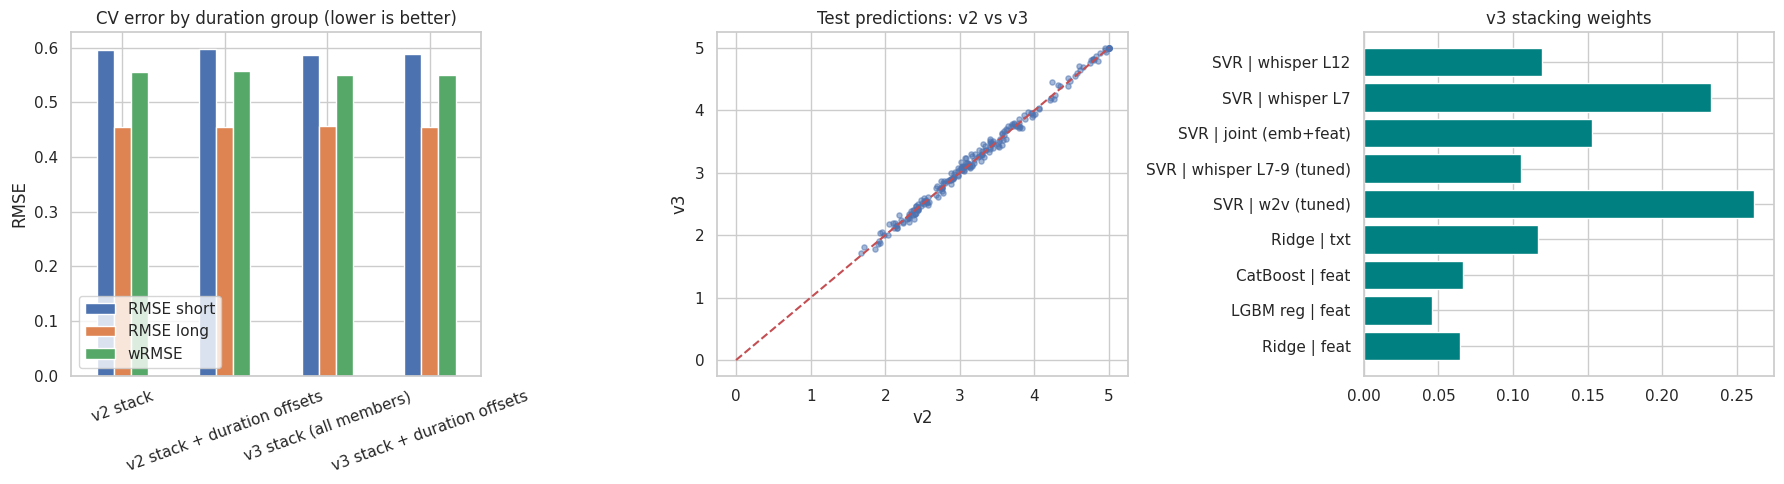

v2 vs v3 test-prediction correlation: 0.9972 | mean abs difference: 0.0488


,filename,label
0,audio_128.wav,3.2632
1,audio_156.wav,4.0444
2,audio_19.wav,4.7136
3,audio_108.wav,1.9063
4,audio_206.wav,2.1477


In [45]:
# in-sample RMSE (required in the final notebook) and honest CV for the chosen v3 model
print("=" * 66)
print(f" v3 TRAINING RMSE (in-sample):              {rmse(y, v3_train):.4f}")
print(f" v3 CV RMSE / test-mix weighted RMSE:       {cmp.loc[best_variant, 'RMSE']:.4f} / {cmp.loc[best_variant, 'wRMSE']:.4f}")
print(f" v3 CV Pearson:                             {cmp.loc[best_variant, 'Pearson']:.4f}")
print(f" v2 CV RMSE / test-mix weighted RMSE:       {cmp.loc['v2 stack', 'RMSE']:.4f} / {cmp.loc['v2 stack', 'wRMSE']:.4f}")
print("=" * 66)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
cmp[["RMSE short", "RMSE long", "wRMSE"]].plot(kind="bar", ax=ax[0], rot=20); ax[0].set(title="CV error by duration group (lower is better)", ylabel="RMSE")
ax[0].legend(loc="lower left")
ax[1].scatter(v2_test, v3_test, alpha=.5, s=14); ax[1].plot([0, 5], [0, 5], "r--"); ax[1].set(title="Test predictions: v2 vs v3", xlabel="v2", ylabel="v3")
ax[2].barh(pd.Series(w_, index=names_b)[lambda s: s > 0].index, pd.Series(w_, index=names_b)[lambda s: s > 0].values, color="teal"); ax[2].set(title="v3 stacking weights")
plt.tight_layout(); plt.show()
print("v2 vs v3 test-prediction correlation:", round(pear(v2_test, v3_test), 4), "| mean abs difference:", round(float(np.abs(v2_test - v3_test).mean()), 4))

if WIN:
    sub3 = pd.DataFrame({"filename": test_df["filename"].values, "label": np.round(v3_test, 4)})
    assert len(sub3) == len(test_df) and sub3["label"].between(0, 5).all() and sub3["label"].notna().all()
    sub3.to_csv("/content/submission_v3.csv", index=False); display(sub3.head())
else:
    print("v3 did not beat v2 by a clear margin -> keep submission_v2.csv.")

# Part D — v4: bigger encoder, richer pooling, an attentive head, and test-mix training

**Where the remaining error is.** Your own diagnostics showed (i) 69% of test clips are short (~45 s) but only 24% of train clips are, and short clips are the hard ones (RMSE ≈ 0.59 vs 0.46); (ii) the strongest signal comes from the Whisper encoder, whose features are **mean-pooled** (all temporal structure is thrown away); (iii) the text-only grammar features alone barely beat the mean (RMSE 1.06). Refinements of v3 (more stack members, retuning) gave ~0.002 — that path is exhausted. v4 therefore changes the *signal*, not just the blend:

| Step | Change | Why it might help |
|---|---|---|
| D.1 | **Larger Whisper encoder** (`whisper-medium.en` by default; `large-v3` optional), per-layer **mean + std** statistics, plus a frame-level cache | v1→v3 gained most from swapping wav2vec2 for Whisper-small; a bigger encoder may continue that trend. Std captures *variability* (hesitation, prosody) that a mean hides. |
| D.2 | Layer sweep on the new encoder | find where the grammar/fluency signal lives |
| D.3 | Frozen-embedding members (band-mean, mean+std, best layer, kernel ridge) | strong, stable base models |
| D.4 | **Test-mix importance-weighted SVR** and **crop-augmented SVR** | train for the test distribution (69% short clips): upweight short clips; crops of long clips mimic shorter recordings |
| D.5 | **Attentive-pooling head** trained on frame-level features with random crops | learns *which moments* matter (e.g. hesitations, disfluent stretches) instead of averaging everything |
| D.6 | v4 stack: all members, test-mix weighted stackers | final blend |
| D.7 | v1 → v4 comparison, submissions | adopted only if it beats v3 by a clear margin |

**Honest expectation.** These are hypotheses, not guarantees. Each step prints its own cross-validated score, and v4 is only adopted if it beats v3 on the test-mix weighted CV by more than 0.003. Everything is scored on the same repeated, duration-aware folds as v3, so the v1 → v3 and v3 → v4 differences are directly comparable. Extra runtime: ≈ 15 min (medium encoder extraction) + ≈ 10 min (attentive head) on a T4 GPU.

## D.1 Larger Whisper encoder: per-layer statistics + frame-level cache
For every clip the encoder is run on 30 s windows (its native input). We keep:
* **per-layer time-mean and time-std** of every transformer layer (for the layer sweep and frozen-embedding models);
* a **frame-level cache** of the average of the upper-middle layers (layers ≈ 42%–100% of depth, the range that was flat-and-best for Whisper-small), average-pooled ×4 to 12.5 frames/s, for the attentive head and the crop-augmented SVR.

Padding added to fill a short window is excluded from every statistic.

In [46]:
import torch.nn as nn
import torch.nn.functional as TF
from sklearn.linear_model import Ridge
from transformers import WhisperFeatureExtractor, WhisperModel as HFWhisperModel

V4_ENC = "openai/whisper-medium.en"    # "openai/whisper-small.en" (fast) | "openai/whisper-medium.en" (default) | "openai/whisper-large-v3" (strongest, ~3x slower)
POOL, MAXT = 4, 800                    # encoder = 50 frames/s -> pooled x4 = 12.5/s; 800 frames = 64 s (clips are <= ~61 s)
tag4 = V4_ENC.split("/")[-1]
F_STATS, F_FR, F_LEN = f"{WORK}/v4_stats_{tag4}.npy", f"{WORK}/v4_frames_{tag4}.npy", f"{WORK}/v4_len_{tag4}.npy"

if all(os.path.exists(f) for f in (F_STATS, F_FR, F_LEN)):
    w4_stats, w4_fr, w4_len = np.load(F_STATS), np.load(F_FR), np.load(F_LEN)
else:
    wfe4 = WhisperFeatureExtractor.from_pretrained(V4_ENC)
    enc4 = HFWhisperModel.from_pretrained(V4_ENC).encoder.to(DEVICE).eval()
    if DEVICE == "cuda": enc4 = enc4.half()
    gc.collect()
    L4n, d4n = enc4.config.encoder_layers, enc4.config.d_model
    n_hid_, b0_ = L4n + 1, int(round(0.42 * L4n))
    N_ = len(all_df)
    w4_stats = np.zeros((N_, n_hid_, 2 * d4n), np.float16)          # [mean | std] per layer
    w4_fr = np.zeros((N_, MAXT, d4n), np.float16)                   # frame cache (band-averaged, pooled)
    w4_len = np.ones(N_, dtype=np.int64)
    for i, pth in enumerate(tqdm(all_df["path"], desc=f"{tag4} encoder")):
        wav, _ = librosa.load(pth, sr=SR, mono=True)
        chunks = [wav[j:j + 30 * SR] for j in range(0, max(len(wav), 1), 30 * SR)]
        chunks = [c for c in chunks if len(c) >= SR] or [wav if len(wav) else np.zeros(SR, np.float32)]
        s1 = torch.zeros(n_hid_, d4n, device=DEVICE); s2 = torch.zeros_like(s1); n_tot, parts = 0, []
        for c in chunks:
            x = wfe4(c, sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE)
            if DEVICE == "cuda": x = x.half()
            with torch.no_grad(): hs = enc4(x, output_hidden_states=True).hidden_states     # (L+1) x (1, 1500, d)
            nv = max(1, int(len(c) / SR * 50))                                              # valid (non-padding) frames
            H = torch.stack([h[0, :nv].float() for h in hs])                                # (L+1, nv, d)
            s1 += H.sum(1); s2 += (H ** 2).sum(1); n_tot += nv
            band = H[b0_:].mean(0); k = nv // POOL
            if k > 0: parts.append(band[:k * POOL].reshape(k, POOL, d4n).mean(1))
        mu = s1 / n_tot; sd = (s2 / n_tot - mu ** 2).clamp_min(0).sqrt()
        w4_stats[i] = torch.cat([mu, sd], 1).cpu().numpy().astype(np.float16)
        if parts:
            Fr = torch.cat(parts, 0)[:MAXT]; w4_fr[i, :len(Fr)] = Fr.cpu().numpy().astype(np.float16); w4_len[i] = len(Fr)
    np.save(F_STATS, w4_stats); np.save(F_FR, w4_fr); np.save(F_LEN, w4_len)
    del enc4; gc.collect(); torch.cuda.empty_cache()

w4_stats, w4_fr = np.nan_to_num(w4_stats.astype(np.float32)), np.nan_to_num(w4_fr)
n_hid = w4_stats.shape[1]; d4 = w4_stats.shape[2] // 2; L4 = n_hid - 1
b0 = int(round(0.42 * L4)); B4 = list(range(b0, n_hid))             # upper-middle "band" of layers
print(f"{tag4}: per-layer stats {w4_stats.shape} | frame cache {w4_fr.shape} | band = layers {B4[0]}..{B4[-1]} of {L4}")

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.95k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.06GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/947 [00:00<?, ?it/s]

whisper-medium.en encoder:   0%|          | 0/985 [00:00<?, ?it/s]

whisper-medium.en: per-layer stats (985, 25, 2048) | frame cache (985, 800, 1024) | band = layers 10..24 of 24


## D.2 Layer sweep on the new encoder
Same SVR on each layer's time-mean (one repeat, tuning folds). The red dashed line is Whisper-small's best layer from the v2 sweep, for reference.

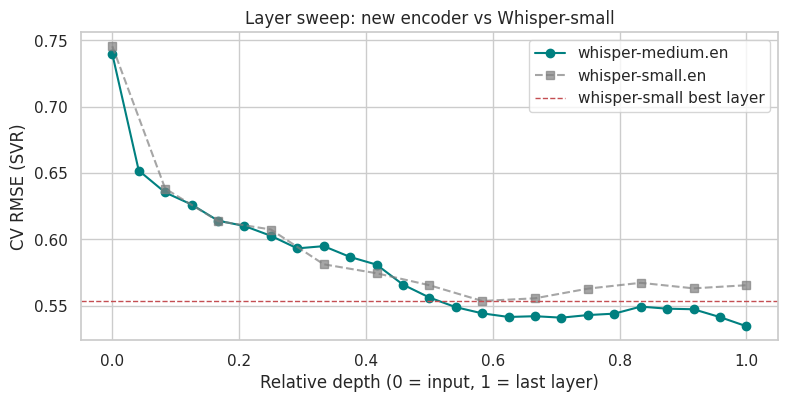

best layer 24: RMSE 0.5346  (Whisper-small best: 0.5536)


In [47]:
sweep4 = []
for L in range(n_hid):
    r = cv_repeated(lambda: svr_f(d=d4), w4_stats[:n_tr, L, :d4], folds_by_rep=rep_folds[:1])
    sweep4.append((L, r["rmse_mean"], r["pearson_mean"]))
sweep4 = pd.DataFrame(sweep4, columns=["layer", "rmse", "pearson"])
BEST_L4 = int(sweep4.sort_values("rmse").layer.iloc[0])

plt.figure(figsize=(9, 4))
plt.plot(sweep4.layer / L4, sweep4.rmse, "o-", color="teal", label=tag4)
plt.plot(sweep.layer / (len(sweep) - 1), sweep.rmse, "s--", color="gray", alpha=.7, label=WH_ENC.split("/")[-1])
plt.axhline(sweep.rmse.min(), color="r", ls="--", lw=1, label="whisper-small best layer")
plt.xlabel("Relative depth (0 = input, 1 = last layer)"); plt.ylabel("CV RMSE (SVR)"); plt.title("Layer sweep: new encoder vs Whisper-small"); plt.legend(); plt.show()
print(f"best layer {BEST_L4}: RMSE {sweep4.rmse.min():.4f}  (Whisper-small best: {sweep.rmse.min():.4f})")

## D.3 Frozen-embedding members
The standardiser is fitted on all 985 clips (unsupervised — no labels — so no leakage), as in v3. Hyper-parameters are tuned on the separate tuning folds, scored by the test-mix weighted RMSE.

In [48]:
mean4 = w4_stats[:, B4, :d4].mean(1)                                   # band-averaged time-mean (985, d)
std4 = w4_stats[:, B4, d4:].mean(1)                                    # band-averaged time-std
Z_mean = StandardScaler().fit_transform(mean4)
Z_ms = StandardScaler().fit_transform(np.hstack([mean4, std4]))
Z_best = StandardScaler().fit_transform(w4_stats[:, BEST_L4, :d4])

def svr_mk(d): return lambda C, eps, g: SVR(C=C, epsilon=eps, gamma=g / d)
def svr_from(bp, d): return lambda: SVR(C=bp["C"], epsilon=bp["eps"], gamma=bp["g"] / d)
GRID = {"C": [3, 10, 30], "eps": [0.1, 0.2], "g": [0.1, 0.3, 1.0]}

bp_mean = tune3(svr_mk(d4), Z_mean[:n_tr], GRID, f"SVR on {tag4} band-mean")
M_MEAN = f"SVR | {tag4} band-mean"
run3(M_MEAN, svr_from(bp_mean, d4), Z_mean[:n_tr], Z_mean[n_tr:])

bp_ms = tune3(svr_mk(2 * d4), Z_ms[:n_tr], GRID, f"SVR on {tag4} band mean+std")
M_MS = f"SVR | {tag4} mean+std"
run3(M_MS, svr_from(bp_ms, 2 * d4), Z_ms[:n_tr], Z_ms[n_tr:])

M_BEST = f"SVR | {tag4} L{BEST_L4}"
run3(M_BEST, svr_from(bp_mean, d4), Z_best[:n_tr], Z_best[n_tr:])

def krr4(alpha, g):
    return TransformedTargetRegressor(regressor=KernelRidge(alpha=alpha, kernel="rbf", gamma=g / d4), transformer=StandardScaler())
bk4 = tune3(krr4, Z_mean[:n_tr], {"alpha": [0.3, 1.0, 3.0], "g": [0.1, 0.3, 1.0]}, f"Kernel ridge on {tag4} band-mean")
M_KRR = f"KRR | {tag4} band-mean"
run3(M_KRR, lambda: krr4(bk4["alpha"], bk4["g"]), Z_mean[:n_tr], Z_mean[n_tr:])


SVR on whisper-medium.en band-mean: top 3


,C,eps,g,wRMSE
7,10,0.1,0.3,0.5631
13,30,0.1,0.3,0.5632
1,3,0.1,0.3,0.5657


SVR | whisper-medium.en band-mean wRMSE=0.5541 | RMSE=0.5029 (short 0.587 / long 0.474) | r=0.9140 | train RMSE=0.1007

SVR on whisper-medium.en band mean+std: top 3


,C,eps,g,wRMSE
1,3,0.1,0.3,0.5581
7,10,0.1,0.3,0.5582
13,30,0.1,0.3,0.5585


SVR | whisper-medium.en mean+std wRMSE=0.5584 | RMSE=0.5193 (short 0.584 / long 0.498) | r=0.9086 | train RMSE=0.2230
SVR | whisper-medium.en L24    wRMSE=0.5683 | RMSE=0.5186 (short 0.600 / long 0.491) | r=0.9081 | train RMSE=0.0947

Kernel ridge on whisper-medium.en band-mean: top 3


,alpha,g,wRMSE
1,0.3,0.3,0.5644
2,0.3,1.0,0.5760
0,0.3,0.1,0.5838


KRR | whisper-medium.en band-mean wRMSE=0.5610 | RMSE=0.5212 (short 0.587 / long 0.499) | r=0.9091 | train RMSE=0.3214


{'oof_reps': [array([3.33190225, 2.71612191, 3.05331531, 2.21308669, 2.27735424,
         2.49603727, 2.48435693, 3.57513715, 3.49534289, 4.19910563,
         3.78119702, 3.01228098, 2.82304565, 3.21393403, 2.42330446,
         2.46513258, 4.3209602 , 0.        , 1.93755436, 4.30235579,
         3.52179538, 3.39971146, 4.4319239 , 2.85127247, 3.515785  ,
         4.02238105, 3.19257968, 3.81756339, 3.01711845, 3.56159723,
         0.        , 3.04957978, 2.77592914, 2.59584496, 2.97696588,
         2.65120108, 4.46995182, 3.49735632, 3.53851359, 4.02714198,
         3.03335522, 0.47002672, 3.98019092, 3.62193197, 2.82430844,
         3.99448767, 2.02427589, 2.22161163, 2.75686618, 0.13946754,
         4.26369893, 1.07571453, 3.12145093, 3.42483784, 2.64119923,
         4.73831778, 4.26704122, 3.23395269, 3.6484648 , 4.66176516,
         3.6591487 , 1.74204057, 2.42580461, 3.03740493, 4.10150837,
         4.55173825, 5.        , 5.        , 2.20158363, 4.94659803,
         4.0273338 , 5

## D.4 Train for the test distribution: importance-weighted SVR and crop-augmented SVR
Models in this section take **global row indices** (train rows are `0..768`, test rows follow), so the same code serves plain, weighted, augmented and neural models.

* **Importance weighting** (`w_tr`, from v3) makes the training mix look like the test mix: short clips get weight ≈ 2.9, long clips ≈ 0.4. SVR supports per-sample weights directly.
* **Crop augmentation**: from the frame cache we build embeddings of three crops (start / middle / end, each 75% of the clip). Training uses the full clip *and* its crops (4× the rows, same label); prediction averages the model over the full clip and the crops (test-time augmentation).

In [49]:
N_ALL = len(all_df); TR_IDX, TE_IDX = np.arange(n_tr), np.arange(n_tr, N_ALL)
ln_f = w4_len

def frame_mean(i, s, e): return w4_fr[i, s:e].astype(np.float32).mean(0)
V_full = np.stack([frame_mean(i, 0, ln_f[i]) for i in range(N_ALL)])
views = [V_full]
for mode in ("start", "mid", "end"):
    V = np.zeros_like(V_full)
    for i, Ln in enumerate(ln_f):
        c = max(int(Ln * 0.75), 1); s = {"start": 0, "mid": (Ln - c) // 2, "end": Ln - c}[mode]
        V[i] = frame_mean(i, s, s + c)
    views.append(V)
sc_f = StandardScaler().fit(V_full)
VZ = [sc_f.transform(v) for v in views]                                  # same scaler for full clips and crops

class SVRRows:
    """SVR on a fixed matrix covering ALL clips; optional per-sample weights."""
    def __init__(self, X, C, eps, g, w=None): self.X, self.C, self.eps, self.g, self.w = X, C, eps, g, w
    def fit(self, tr):
        self.m = SVR(C=self.C, epsilon=self.eps, gamma=self.g / self.X.shape[1]).fit(
            self.X[tr], y[tr], sample_weight=None if self.w is None else self.w[tr]); return self
    def predict(self, rows): return self.m.predict(self.X[rows])

class CropSVR:
    """Train on full clips + crops; predict by averaging over full clip + crops."""
    def __init__(self, vs, C, eps, g): self.vs, self.C, self.eps, self.g = vs, C, eps, g
    def fit(self, tr):
        X = np.vstack([v[tr] for v in self.vs]); yy = np.tile(y[tr], len(self.vs))
        self.m = SVR(C=self.C, epsilon=self.eps, gamma=self.g / X.shape[1]).fit(X, yy); return self
    def predict(self, rows): return np.mean([self.m.predict(v[rows]) for v in self.vs], axis=0)

def run4(name, make_model):
    """Repeated CV for models that work on global row indices; stored in RES3 so the stackers can use it."""
    t0 = time.time(); oof_reps, tp, k = [], np.zeros(len(TE_IDX)), 0
    for folds in REP3:
        o = np.zeros(n_tr)
        for tr, va in folds:
            m = make_model().fit(tr); o[va] = m.predict(va); tp += m.predict(TE_IDX); k += 1
        oof_reps.append(np.clip(o, 0, 5))
    train = np.clip(make_model().fit(TR_IDX).predict(TR_IDX), 0, 5)
    r = {"oof_reps": oof_reps, "oof": np.mean(oof_reps, 0), "test": np.clip(tp / k, 0, 5), "train": train, "train_rmse": rmse(y, train)}
    r["sum"] = mean_summary(oof_reps); RES3[name] = r; s = r["sum"]
    print(f"{name:34s} wRMSE={s['wRMSE']:.4f} | RMSE={s['RMSE']:.4f} (short {s['RMSE short']:.3f} / long {s['RMSE long']:.3f}) | r={s['Pearson']:.4f} | train RMSE={r['train_rmse']:.4f} [{time.time() - t0:.0f}s]")
    return r

bp_f = tune3(svr_mk(d4), VZ[0][:n_tr], GRID, "SVR on frame-cache band-mean")
M_W = f"SVR | {tag4} weighted"; M_CROP = f"SVR | {tag4} crop-aug+TTA"
run4(M_W, lambda: SVRRows(VZ[0], bp_f["C"], bp_f["eps"], bp_f["g"], w=w_tr))
run4(M_CROP, lambda: CropSVR(VZ, bp_f["C"], bp_f["eps"], bp_f["g"]))


SVR on frame-cache band-mean: top 3


,C,eps,g,wRMSE
7,10,0.1,0.3,0.5633
13,30,0.1,0.3,0.5633
1,3,0.1,0.3,0.5657


SVR | whisper-medium.en weighted   wRMSE=0.5505 | RMSE=0.5088 (short 0.577 / long 0.486) | r=0.9120 | train RMSE=0.1851 [5s]
SVR | whisper-medium.en crop-aug+TTA wRMSE=0.5521 | RMSE=0.4970 (short 0.587 / long 0.466) | r=0.9163 | train RMSE=0.0624 [49s]


{'oof_reps': [array([3.49101734e+00, 2.77194050e+00, 2.98527060e+00, 2.50715791e+00,
         2.19814082e+00, 2.42158472e+00, 1.88392583e+00, 3.45226521e+00,
         3.73686540e+00, 3.77884498e+00, 4.08813753e+00, 2.89079130e+00,
         2.83943971e+00, 2.88046084e+00, 2.27721661e+00, 2.31934329e+00,
         4.40814028e+00, 0.00000000e+00, 1.90802165e+00, 4.56760096e+00,
         3.48625950e+00, 3.35802375e+00, 4.40474780e+00, 2.89276515e+00,
         3.77954879e+00, 4.45088280e+00, 3.59265370e+00, 3.95068795e+00,
         2.67740707e+00, 3.61379360e+00, 0.00000000e+00, 3.22398394e+00,
         3.00070263e+00, 2.81630933e+00, 2.90864796e+00, 2.47103938e+00,
         4.74471799e+00, 3.18950357e+00, 3.23924930e+00, 4.41575147e+00,
         2.87259375e+00, 6.15734156e-01, 4.08980813e+00, 3.50974745e+00,
         2.70982894e+00, 4.17167960e+00, 2.43125288e+00, 2.22607659e+00,
         2.53533588e+00, 2.63241166e-02, 4.08283162e+00, 7.74620236e-01,
         3.05360152e+00, 3.25610379e+00

## D.5 Attentive-pooling head on frame-level features
Mean pooling treats every moment equally. This small network (LayerNorm → Linear → GELU, then **attention pooling** + mean pooling → MLP) is trained on the frame-level cache and can learn to focus on informative moments (hesitations, broken constructions). Regularisation: dropout, weight decay, one-cycle LR, **random temporal crops (60–100% of the clip) at every step**, and an ensemble of 3 seeds. Targets are standardised; the encoder stays frozen. Evaluated with exactly the same repeated folds as every other member.

*Needs a GPU (skipped on CPU). If it is too slow, lower `HEAD_CFG["epochs"]` or `["seeds"]`.*

In [50]:
HEAD_CFG = dict(epochs=40, bs=32, lr=5e-4, wd=0.05, hid=256, drop=0.3, seeds=3, crop=(0.6, 1.0))
y_mu, y_sd = float(y.mean()), float(y.std())
M_HEAD = f"Head | attn-pool {tag4}"

if DEVICE == "cuda":
    FR_T = torch.from_numpy(np.ascontiguousarray(w4_fr.astype(np.float16))).to(DEVICE)       # (N, MAXT, d) on GPU
    LN_T = torch.from_numpy(w4_len).to(DEVICE); AR = torch.arange(MAXT, device=DEVICE)

    class AttnHead(nn.Module):
        def __init__(self, d, hid, drop):
            super().__init__()
            self.proj = nn.Sequential(nn.LayerNorm(d), nn.Dropout(drop), nn.Linear(d, hid), nn.GELU())
            self.att = nn.Linear(hid, 1)
            self.out = nn.Sequential(nn.Dropout(drop), nn.Linear(2 * hid, 64), nn.GELU(), nn.Linear(64, 1))
        def forward(self, x, mask):                                   # x (B,T,d); mask (B,T) True = use this frame
            z = self.proj(x)
            a = torch.softmax(self.att(z).squeeze(-1).masked_fill(~mask, -1e4), dim=1)
            pooled = (a.unsqueeze(-1) * z).sum(1)
            mean = (z * mask.unsqueeze(-1)).sum(1) / mask.sum(1, keepdim=True).clamp_min(1)
            return self.out(torch.cat([pooled, mean], -1)).squeeze(-1)

    class HeadModel:
        def __init__(self, cfg=HEAD_CFG): self.cfg = cfg
        def _batch(self, idx, train):
            x, ln = FR_T[idx].float(), LN_T[idx]
            mask = AR[None, :] < ln[:, None]
            if train:                                                 # random temporal crop
                lo, hi = self.cfg["crop"]
                cl = (ln.float() * (lo + (hi - lo) * torch.rand(len(idx), device=DEVICE))).long().clamp_min(1)
                st = ((ln - cl).float() * torch.rand(len(idx), device=DEVICE)).long()
                mask = mask & (AR[None, :] >= st[:, None]) & (AR[None, :] < (st + cl)[:, None])
            return x, mask
        def fit(self, tr):
            c = self.cfg; self.nets = []
            yt = torch.tensor((y[tr] - y_mu) / y_sd, dtype=torch.float32, device=DEVICE); tr_t = torch.tensor(tr, device=DEVICE)
            for s in range(c["seeds"]):
                torch.manual_seed(SEED + s)
                net = AttnHead(FR_T.shape[2], c["hid"], c["drop"]).to(DEVICE)
                opt = torch.optim.AdamW(net.parameters(), lr=c["lr"], weight_decay=c["wd"])
                steps = c["epochs"] * math.ceil(len(tr) / c["bs"])
                sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=c["lr"], total_steps=steps)
                net.train()
                for ep in range(c["epochs"]):
                    perm = torch.randperm(len(tr), device=DEVICE)
                    for b in range(0, len(tr), c["bs"]):
                        pi = perm[b:b + c["bs"]]; x, m = self._batch(tr_t[pi], True)
                        loss = TF.mse_loss(net(x, m), yt[pi]); opt.zero_grad(); loss.backward(); opt.step(); sched.step()
                self.nets.append(net.eval())
            return self
        def predict(self, rows):
            rows_t = torch.tensor(rows, device=DEVICE); outs = []
            with torch.no_grad():
                for net in self.nets:
                    outs.append(torch.cat([net(*self._batch(rows_t[b:b + 64], False)).float().cpu() for b in range(0, len(rows), 64)]).numpy())
            return np.mean(outs, 0) * y_sd + y_mu

    run4(M_HEAD, lambda: HeadModel())
    del FR_T; gc.collect(); torch.cuda.empty_cache()
else:
    print("No GPU -> attentive head skipped.")

Head | attn-pool whisper-medium.en wRMSE=0.5906 | RMSE=0.5399 (short 0.623 / long 0.511) | r=0.9031 | train RMSE=0.2481 [721s]


## D.6 v1-equivalent members on the common folds, then the v4 stack
First the two v1 members that v3 no longer uses are re-scored on the same folds, so that **v1, v2, v3 and v4 are all evaluated identically** (repeated, duration-aware folds; nested CV for the stacker). Then the v4 stack is built from all v3 members plus the new v4 members, using several stackers (plain / test-mix weighted / ridge-regularised, all non-negative).

In [51]:
# v1-equivalent members on the common (REP3) folds
run3("LGBM old | feat", lgbm_old, X_feat, Xt_feat)
run3("SVR | w2v old", lambda: svr_f(3.0, 0.2, 1.0, X_aud.shape[1]), X_aud, Xt_aud)
V1N = ["Ridge | feat", "LGBM old | feat", "CatBoost | feat", "Ridge | txt", "SVR | w2v old"]

LGBM old | feat                wRMSE=0.6647 | RMSE=0.6285 (short 0.688 / long 0.609) | r=0.8618 | train RMSE=0.1065
SVR | w2v old                  wRMSE=0.6631 | RMSE=0.5798 (short 0.714 / long 0.531) | r=0.8857 | train RMSE=0.2164


In [52]:
from sklearn.linear_model import Ridge
V4_NEW = [n for n in RES3 if n.startswith(("SVR | whisper-", "KRR | whisper-", "Head |")) and n not in V3N and n not in V1N]
V4N = V3N + V4_NEW
print("New v4 members:", V4_NEW)

STACKERS = {"LR":                        (lambda: LinearRegression(positive=True), False),
            "LR, test-mix weighted":     (lambda: LinearRegression(positive=True), True),
            "Ridge+ (a=3), weighted":    (lambda: Ridge(alpha=3.0, positive=True), True),
            "Ridge+ (a=30), weighted":   (lambda: Ridge(alpha=30.0, positive=True), True)}

def stack4_eval(names, kind):
    mk, wt = STACKERS[kind]; out = []
    for r in range(N_REPEATS):
        P = np.column_stack([RES3[n]["oof_reps"][r] for n in names]); s = np.zeros(n_tr)
        for tr, va in KFold(5, shuffle=True, random_state=SEED + r).split(P):
            m = mk(); m.fit(P[tr], y[tr], sample_weight=w_tr[tr] if wt else None); s[va] = m.predict(P[va])
        out.append(summarize(np.clip(s, 0, 5)))
    return pd.DataFrame(out).mean().to_dict()

def stack4_final(names, kind):
    mk, wt = STACKERS[kind]
    O, T, TR = [np.column_stack([RES3[n][k] for n in names]) for k in ("oof", "test", "train")]
    m = mk().fit(O, y, sample_weight=w_tr if wt else None)
    return m, np.clip(m.predict(T), 0, 5), np.clip(m.predict(TR), 0, 5)

rows4 = {}
for set_name, nm in (("v3 members", V3N), ("v3 + v4 members", V4N)):
    for kind in STACKERS: rows4[f"{set_name} | {kind}"] = stack4_eval(nm, kind)
cmp4 = pd.DataFrame(rows4).T; display(cmp4.round(4))

best4 = cmp4.loc[[i for i in cmp4.index if i.startswith("v3 + v4")], "wRMSE"].idxmin()
kind4 = best4.split(" | ")[1]
v3_wr = cmp.loc[best_variant, "wRMSE"]
WIN4 = cmp4.loc[best4, "wRMSE"] < v3_wr - 0.003
print(f"Best v4 variant: {best4}  wRMSE={cmp4.loc[best4, 'wRMSE']:.4f}   (v3: {v3_wr:.4f})  ->  adopt v4: {WIN4}")
m4, v4_test, v4_train = stack4_final(V4N, kind4)
w4_ = pd.Series(m4.coef_, index=V4N); print("\nv4 stack weights (non-zero):"); print(w4_[w4_ > 1e-3].round(3).sort_values(ascending=False).to_string())

New v4 members: ['SVR | whisper-medium.en band-mean', 'SVR | whisper-medium.en mean+std', 'SVR | whisper-medium.en L24', 'KRR | whisper-medium.en band-mean', 'SVR | whisper-medium.en weighted', 'SVR | whisper-medium.en crop-aug+TTA', 'Head | attn-pool whisper-medium.en']


,RMSE,wRMSE,RMSE short,RMSE long,Pearson
v3 members | LR,0.4899,0.5492,0.5864,0.4558,0.9186
"v3 members | LR, test-mix weighted",0.5013,0.5465,0.5754,0.4759,0.9145
"v3 members | Ridge+ (a=3), weighted",0.5009,0.5455,0.5740,0.4759,0.9147
"v3 members | Ridge+ (a=30), weighted",0.4990,0.5447,0.5739,0.4734,0.9155
v3 + v4 members | LR,0.4781,0.5304,0.5634,0.4483,0.9226
"v3 + v4 members | LR, test-mix weighted",0.4870,0.5323,0.5611,0.4616,0.9195
"v3 + v4 members | Ridge+ (a=3), weighted",0.4864,0.5290,0.5562,0.4626,0.9197
"v3 + v4 members | Ridge+ (a=30), weighted",0.4866,0.5292,0.5564,0.4627,0.9198


Best v4 variant: v3 + v4 members | Ridge+ (a=3), weighted  wRMSE=0.5290   (v3: 0.5492)  ->  adopt v4: True

v4 stack weights (non-zero):
SVR | whisper-medium.en crop-aug+TTA    0.200
SVR | whisper-medium.en band-mean       0.167
Ridge | txt                             0.153
SVR | whisper-medium.en L24             0.140
SVR | whisper-medium.en weighted        0.125
Ridge | feat                            0.111
SVR | w2v (tuned)                       0.105
Ridge | feat_pm                         0.074
CatBoost | feat                         0.038
SVR | whisper L12                       0.025
SVR | whisper-medium.en mean+std        0.023
CatBoost | feat_pm                      0.009
LGBM reg | feat                         0.006
Ridge | feat_pm_nodur                   0.004


## D.7 v1 → v4: one comparison, and the submissions
Every row is scored on the **same repeated, duration-aware folds**, with the stacker cross-validated too. `wRMSE` re-weights errors to the test duration mix (69% short clips) and is the best available proxy for test performance. *Training RMSE* is the in-sample error (required by the assignment; optimistic by construction).

,RMSE,wRMSE,RMSE short,RMSE long,Pearson,Train RMSE,gain in RMSE vs previous,gain in wRMSE vs previous
v1 (5 models),0.5216,0.5804,0.6174,0.4881,0.9072,0.1953,NaN,NaN
"v2 (+ Whisper-small, tuned)",0.4916,0.5558,0.5957,0.4545,0.9180,0.1533,0.0299,0.0246
v3 (all members),0.4899,0.5492,0.5864,0.4558,0.9186,0.1485,0.0018,0.0066
"v4 (Ridge+ (a=3), weighted)",0.4864,0.5290,0.5562,0.4626,0.9197,0.1709,0.0035,0.0202


CV RMSE gain   v1 -> v3: +0.0317   |   v3 -> v4: +0.0035
wRMSE  gain    v1 -> v3: +0.0312   |   v3 -> v4: +0.0202
v4 adopted as the final model: True


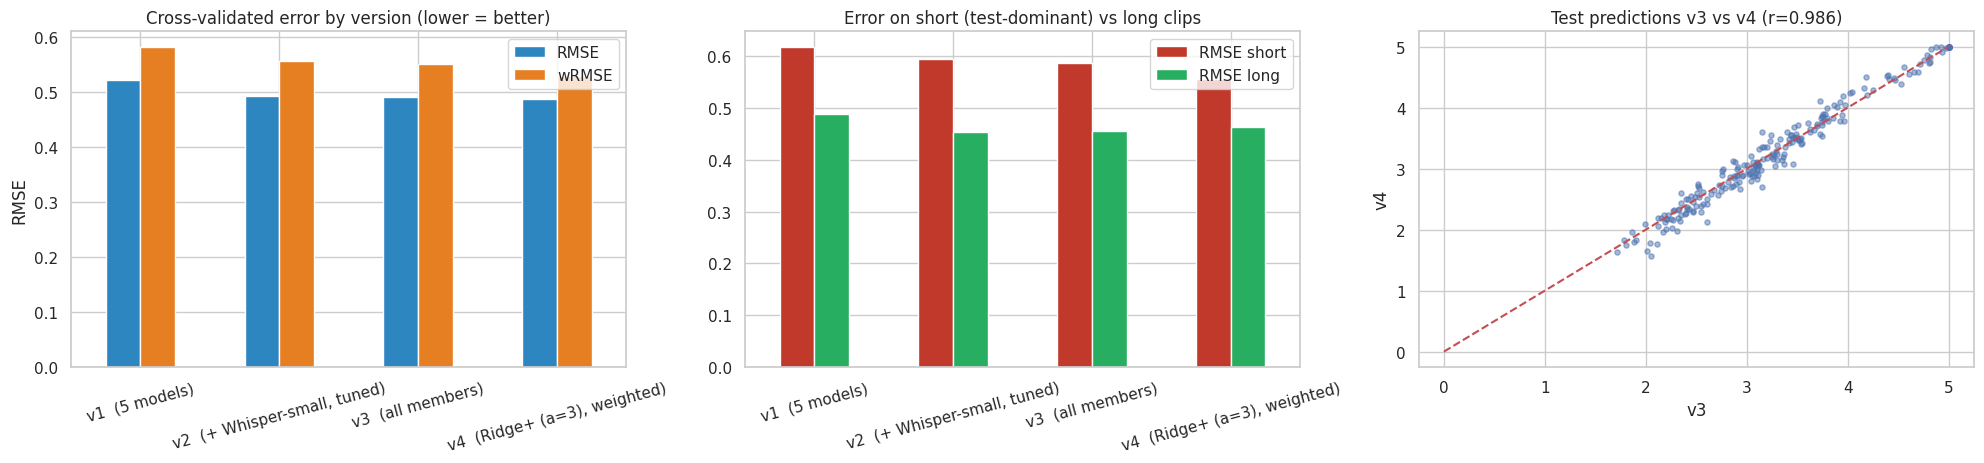

In [53]:
def row_from(summ, train_pred): return {**{k: summ[k] for k in ("RMSE", "wRMSE", "RMSE short", "RMSE long", "Pearson")}, "Train RMSE": rmse(y, train_pred)}
tbl = pd.DataFrame({
    "v1  (5 models)":               row_from(stack_eval(V1N), stack_final(V1N)[2]),
    "v2  (+ Whisper-small, tuned)": row_from(stack_eval(V2N), stack_final(V2N)[2]),
    f"v3  ({best_variant.replace('v3 stack ', '').strip('()')})": row_from(cmp.loc[best_variant].to_dict(), v3_train),
    f"v4  ({kind4})":               row_from(cmp4.loc[best4].to_dict(), v4_train)}).T
tbl["gain in RMSE vs previous"] = -tbl["RMSE"].diff(); tbl["gain in wRMSE vs previous"] = -tbl["wRMSE"].diff()
display(tbl.round(4))

g13, g34 = tbl["RMSE"].iloc[0] - tbl["RMSE"].iloc[2], tbl["RMSE"].iloc[2] - tbl["RMSE"].iloc[3]
gw13, gw34 = tbl["wRMSE"].iloc[0] - tbl["wRMSE"].iloc[2], tbl["wRMSE"].iloc[2] - tbl["wRMSE"].iloc[3]
print(f"CV RMSE gain   v1 -> v3: {g13:+.4f}   |   v3 -> v4: {g34:+.4f}")
print(f"wRMSE  gain    v1 -> v3: {gw13:+.4f}   |   v3 -> v4: {gw34:+.4f}")
print("v4 adopted as the final model:", WIN4)

fig, ax = plt.subplots(1, 3, figsize=(20, 4.8))
tbl[["RMSE", "wRMSE"]].plot(kind="bar", ax=ax[0], rot=15, color=["#2e86c1", "#e67e22"]); ax[0].set(title="Cross-validated error by version (lower = better)", ylabel="RMSE")
tbl[["RMSE short", "RMSE long"]].plot(kind="bar", ax=ax[1], rot=15, color=["#c0392b", "#27ae60"]); ax[1].set(title="Error on short (test-dominant) vs long clips")
ax[2].scatter(v3_test, v4_test, alpha=.5, s=14); ax[2].plot([0, 5], [0, 5], "r--"); ax[2].set(title=f"Test predictions v3 vs v4 (r={pear(v3_test, v4_test):.3f})", xlabel="v3", ylabel="v4")
plt.tight_layout(); plt.show()

In [54]:
# ---- write every version's submission; final_submission.csv = the adopted model ----
def save_sub(pred, path):
    s = pd.DataFrame({"filename": test_df["filename"].values, "label": np.round(np.clip(pred, 0, 5), 4)})
    assert len(s) == len(test_df) and s["label"].between(0, 5).all() and s["label"].notna().all()
    s.to_csv(path, index=False); return s

save_sub(stack_test_v1, "/content/submission_v1.csv"); save_sub(v2_test, "/content/submission_v2.csv"); save_sub(v3_test, "/content/submission_v3.csv")
sub4 = save_sub(v4_test, "/content/submission_v4.csv")
FINAL_NAME, final_pred = ("v4", v4_test) if WIN4 else ("v3", v3_test)
final_sub = save_sub(final_pred, "/content/final_submission.csv")
print(f"final_submission.csv = {FINAL_NAME}  |  shape {final_sub.shape}  |  mean prediction {final_pred.mean():.3f} (train mean {y.mean():.3f})")
print("Test-prediction correlations:  v1-v3:", round(pear(stack_test_v1, v3_test), 4), "| v3-v4:", round(pear(v3_test, v4_test), 4))
display(final_sub.head())
try:
    from google.colab import files; files.download("/content/final_submission.csv")
except Exception:
    pass

final_submission.csv = v4  |  shape (216, 2)  |  mean prediction 3.213 (train mean 3.313)
Test-prediction correlations:  v1-v3: 0.9728 | v3-v4: 0.9855


,filename,label
0,audio_128.wav,3.1590
1,audio_156.wav,4.2606
2,audio_19.wav,4.7109
3,audio_108.wav,1.8322
4,audio_206.wav,2.1969


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Part E — v5 experiments: soft test-mix weights, a GEC feasibility gate, and an honest validation check
**Where to paste:** after the last Part D cell (D.7, the one that writes the submissions), before the Report. Everything reuses Part D objects (`RES3, run4, SVRRows, CropSVR, VZ, bp_f, bp_mean, bp_ms, tune3, w_tr, V4N, STACKERS, stack4_eval, stack4_final, cmp4, best4, kind4, v4_test, v4_train, mean4, std4`), so nothing is re-extracted. All new members are scored on the same repeated duration-aware folds (`REP3`) and adopted only by the same rule as before (weighted RMSE better by > 0.003, plain RMSE not worse by more than 0.003).

| Step | Question it answers | GPU? |
|---|---|---|
| E.1 | D.4 trains the SVR with test-mix weights 2.9 (short) vs 0.41 (long), a 7:1 ratio. Is a *softer* ratio (`w**a`, a<1) better? | no |
| E.2 | Does a grammatical-error-correction (GEC) signal explain any of the error the stack still makes? **Cheap gate on 200 clips before paying for all 985.** | yes (small) |
| E.3 | If E.2 passes: full GEC features, new members, stack check | yes |
| E.4 | How optimistic is the stack's CV? Nested CV on a reduced pipeline with scalers fitted inside folds | no |
| E.5 | Pick the final candidate and write `submission_v5.csv` (only if something clearly wins) | no |

**Honest expectation:** E.1 ≈ 0.00-0.005 weighted RMSE, E.2/E.3 ≈ 0-0.01 (Whisper repairs grammar, so GEC may find little), E.4 changes no predictions; it tells you how much to trust the numbers.

## E.1 Softer importance weights for the base SVR
**Why:** `sample_weight` scales each sample's penalty `C`. With weights 2.9 / 0.41 the 587 long training clips are almost ignored (their total weight is 587 x 0.41 ≈ 240 vs 182 x 2.9 ≈ 530 for the short clips), so the model effectively trains on ~182 clips plus a little. A softer exponent `a` (weights `w_tr**a`, renormalised to mean 1) keeps more of the information in the long clips, which share the same grammar signal. `a=0` is unweighted, `a=1` is what D.4 used. We evaluate the whole range with the same SVR, then re-tune `C`/`g` at the best exponent on separate tuning folds, for both the full-clip SVR and the crop-augmented SVR.

RMSE   wRMSE  RMSE short  RMSE long  Pearson
model          exponent a                                                
full clip      0.00        0.5029  0.5541      0.5866     0.4739   0.9140
               0.25        0.5026  0.5530      0.5850     0.4741   0.9141
               0.50        0.5021  0.5510      0.5822     0.4744   0.9143
               0.75        0.5039  0.5497      0.5789     0.4783   0.9137
               1.00        0.5088  0.5505      0.5772     0.4856   0.9120
crop-aug + TTA 0.00        0.4970  0.5521      0.5868     0.4657   0.9163
               0.50        0.4970  0.5521      0.5868     0.4656   0.9163
               1.00        0.4956  0.5491      0.5829     0.4652   0.9168

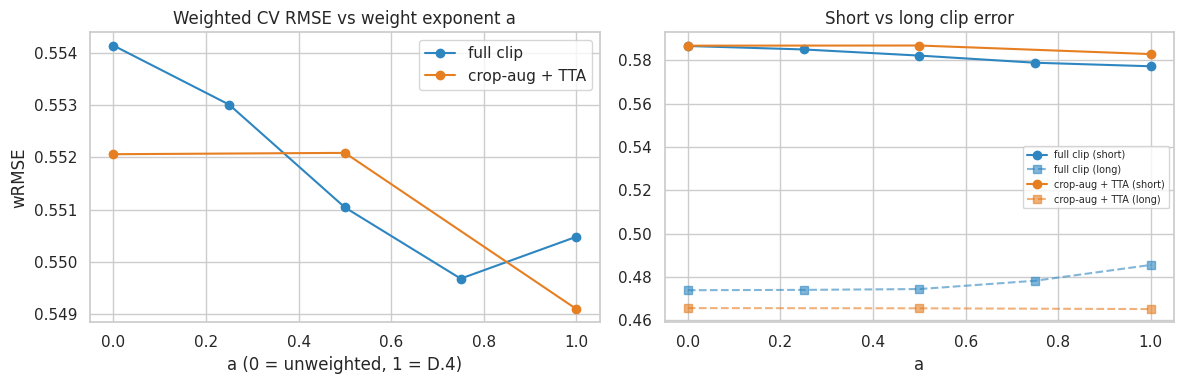

In [56]:
def cv_rows(make_model, folds_by_rep):
    """Repeated CV for models that work on global row indices (SVRRows / CropSVRW). Returns per-repeat OOF predictions."""
    reps = []
    for folds in folds_by_rep:
        o = np.zeros(n_tr)
        for tr, va in folds: o[va] = make_model().fit(tr).predict(va)
        reps.append(np.clip(o, 0, 5))
    return reps

class CropSVRW(CropSVR):
    """CropSVR (train on full clip + crops, average over them at prediction) with optional per-clip weights; crops inherit the clip's weight."""
    def __init__(self, vs, C, eps, g, w=None): super().__init__(vs, C, eps, g); self.w = w
    def fit(self, tr):
        X = np.vstack([v[tr] for v in self.vs]); yy = np.tile(y[tr], len(self.vs))
        sw = None if self.w is None else np.tile(self.w[tr], len(self.vs))
        self.m = SVR(C=self.C, epsilon=self.eps, gamma=self.g / X.shape[1]).fit(X, yy, sample_weight=sw); return self

def wexp(a):
    v = w_tr ** a; return v / v.mean()                       # a=0 -> all ones, a=1 -> the D.4 weights (mean is already 1)

rows = {}
for a in (0.0, 0.25, 0.5, 0.75, 1.0):
    wa = None if a == 0 else wexp(a)
    rows[("full clip", a)] = mean_summary(cv_rows(lambda: SVRRows(VZ[0], bp_f["C"], bp_f["eps"], bp_f["g"], w=wa), REP3))
for a in (0.0, 0.5, 1.0):
    wa = None if a == 0 else wexp(a)
    rows[("crop-aug + TTA", a)] = mean_summary(cv_rows(lambda: CropSVRW(VZ, bp_f["C"], bp_f["eps"], bp_f["g"], w=wa), REP3))
sweep_w = pd.DataFrame(rows).T; sweep_w.index.names = ["model", "exponent a"]
display(sweep_w.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for fam, c in (("full clip", "#2e86c1"), ("crop-aug + TTA", "#e67e22")):
    t = sweep_w.loc[fam]; ax[0].plot(t.index, t["wRMSE"], "o-", color=c, label=fam); ax[1].plot(t.index, t["RMSE short"], "o-", color=c, label=f"{fam} (short)"); ax[1].plot(t.index, t["RMSE long"], "s--", color=c, alpha=.6, label=f"{fam} (long)")
ax[0].set(title="Weighted CV RMSE vs weight exponent a", xlabel="a (0 = unweighted, 1 = D.4)", ylabel="wRMSE"); ax[0].legend()
ax[1].set(title="Short vs long clip error", xlabel="a"); ax[1].legend(fontsize=7); plt.tight_layout(); plt.show()

In [57]:
# ---- re-tune C / g at the best exponent (separate tuning folds), then register as stack members ----
E1 = {}
for fam, make in (("full clip", lambda wa, C, g: SVRRows(VZ[0], C, bp_f["eps"], g, w=wa)),
                  ("crop-aug + TTA", lambda wa, C, g: CropSVRW(VZ, C, bp_f["eps"], g, w=wa))):
    a_best = sweep_w.loc[fam]["wRMSE"].idxmin(); wa = None if a_best == 0 else wexp(a_best)
    tr_rows = []
    for C, g in itertools.product((3, 10, 30), (0.1, 0.3, 1.0)):
        tr_rows.append({"C": C, "g": g, "wRMSE": mean_summary(cv_rows(lambda: make(wa, C, g), TUNE3))["wRMSE"]})
    t = pd.DataFrame(tr_rows).sort_values("wRMSE"); b = t.iloc[0]
    print(f"{fam}: best exponent a={a_best} | tuned C={b.C:g}, g={b.g:g} (tuning wRMSE {b.wRMSE:.4f})")
    name = f"E.1 {fam} {tag4} w^{a_best}"
    run4(name, lambda: make(wa, b.C, b.g)); E1[fam] = name
E1_NAMES = list(E1.values())

full clip: best exponent a=0.75 | tuned C=10, g=0.3 (tuning wRMSE 0.5610)
E.1 full clip whisper-medium.en w^0.75 wRMSE=0.5497 | RMSE=0.5039 (short 0.579 / long 0.478) | r=0.9137 | train RMSE=0.1489 [5s]
crop-aug + TTA: best exponent a=1.0 | tuned C=3, g=0.3 (tuning wRMSE 0.5536)
E.1 crop-aug + TTA whisper-medium.en w^1.0 wRMSE=0.5453 | RMSE=0.5028 (short 0.573 / long 0.479) | r=0.9145 | train RMSE=0.1661 [58s]


## E.2 GEC feasibility gate (200 clips first)
**Idea:** a grammatical-error-correction model rewrites each sentence; *what had to change* (edits per 100 words, share of sentences changed, error types) is a more direct grammar-error measure than CoLA/GPT-2 scores.

**Why a gate:** in your v1 the CoLA and GPT-2 families carried only 6.7% and 1.6% of LightGBM's gain, and Whisper already repairs grammar, so there may be little left for GEC to find. Instead of running all 985 clips and hoping, we run **200 training clips** and ask the question that matters: *do the GEC features correlate with the error the current stack still makes* (its out-of-fold residual `y - stack_oof`)? A feature that only repeats what the stack already knows has ~0 correlation with that residual, however well it correlates with the raw label.

**Gate rule:** pass if any GEC feature has |Spearman with the residual| >= 0.20 (p < 0.01, n=200 so the standard error is about 0.07). The existing grammar features (`cola_mean`, GPT-2 NLL, rule-error rate) are printed as a yardstick.

**Spoken-text handling:** fillers ("um", "uh") and immediate word repeats are removed *before* GEC so they are not counted as grammar errors (disfluency is already measured separately by `tx_fillers` / `tx_repeats`); the originals stay untouched in `text_map`. Punctuation/casing/spelling edits are ignored because they are transcription artefacts.

*Model:* `vennify/t5-base-grammar-correction` (small and fast, prefix `grammar: `). Other GEC models need a different prefix: set `GEC_MODEL` and `GEC_PREFIX` below (e.g. `grammarly/coedit-large` with prefix `"Fix grammatical errors in this sentence: "`). ERRANT (error types) is optional; the core features use only the standard library.

In [58]:
import difflib
from collections import Counter
from scipy.stats import spearmanr
import subprocess, sys
def _load_errant():
    try:
        import errant; return errant.load("en")
    except Exception:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "errant"], capture_output=True)      # Colab: usually enough
        try:
            import errant; return errant.load("en")
        except Exception as e:
            print("ERRANT unavailable ->", type(e).__name__, "(error-type features skipped; the core edit-rate features still work)"); return None
annot = _load_errant(); HAVE_ERRANT = annot is not None

GEC_MODEL, GEC_PREFIX = "vennify/t5-base-grammar-correction", "grammar: "
GEC_FILE = f"{WORK}/gec_pairs.json"
gec_pairs = json.load(open(GEC_FILE)) if os.path.exists(GEC_FILE) else {}          # key -> [[cleaned original sentence, corrected sentence], ...]

_nw = lambda t: re.sub(r"[^a-z' ]", " ", str(t).lower()).split()
_k  = lambda t: re.sub(r"[^a-z']", "", t.lower())
FILL_ = {"um", "uh", "er", "erm", "hmm", "mm", "uhm", "ah", "eh"}

def clean_disfl(s):
    """Remove filler words and immediate word repeats so GEC is not blamed for disfluency."""
    out = []
    for t in s.split():
        if _k(t) in FILL_: continue
        if out and _k(t) != "" and _k(t) == _k(out[-1]): continue
        out.append(t)
    return " ".join(out)

_gec = {}
def run_gec(keys, chunk=100):
    todo = [k for k in keys if k not in gec_pairs]
    if not todo: return
    from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
    if "m" not in _gec:
        _gec["tok"] = AutoTokenizer.from_pretrained(GEC_MODEL); _gec["m"] = AutoModelForSeq2SeqLM.from_pretrained(GEC_MODEL).to(DEVICE).eval()
    tok, m = _gec["tok"], _gec["m"]
    for c0 in range(0, len(todo), chunk):                                        # checkpoint after every chunk of clips
        ks = todo[c0:c0 + chunk]; flat = []
        for k in ks:
            for s in sent_map[k]:
                s = clean_disfl(s)
                if len(s.split()) >= 3: flat.append((k, s))
        flat.sort(key=lambda x: len(x[1])); cors = []
        for b in range(0, len(flat), 32):
            enc = tok([GEC_PREFIX + s for _, s in flat[b:b + 32]], return_tensors="pt", padding=True, truncation=True, max_length=128).to(DEVICE)
            with torch.no_grad(): gen = m.generate(**enc, max_length=128, num_beams=4)
            cors += tok.batch_decode(gen, skip_special_tokens=True)
        for k in ks: gec_pairs[k] = []
        for (k, s), c in zip(flat, cors): gec_pairs[k].append([s, c])
        json.dump(gec_pairs, open(GEC_FILE, "w"))
        print(f"GEC: {min(c0 + chunk, len(todo))}/{len(todo)} clips")

CAT_IGNORE = {"ORTH", "PUNCT", "SPELL", "CONTR"}                                 # transcription artefacts, not grammar
def gec_feats(pairs):
    nan = {c: np.nan for c in GEC_COLS}
    nwn = sum(len(_nw(a)) for a, _ in pairs)
    if not pairs or nwn == 0: return nan
    ins = dele = sub = ops = changed = 0; len_diff = 0; cat = Counter()
    for a, b in pairs:
        wa, wb = _nw(a), _nw(b); len_diff += len(wb) - len(wa); c = 0
        for tag, i1, i2, j1, j2 in difflib.SequenceMatcher(a=wa, b=wb, autojunk=False).get_opcodes():
            if tag == "equal": continue
            c += 1
            if tag == "insert": ins += j2 - j1
            elif tag == "delete": dele += i2 - i1
            else: sub += max(i2 - i1, j2 - j1)
        ops += c; changed += c > 0
        if HAVE_ERRANT:
            try:
                for e in annot.annotate(annot.parse(a), annot.parse(b)):
                    t = e.type[2:]
                    if t in CAT_IGNORE: continue
                    cat["ALL"] += 1; cat[t.split(":")[0]] += 1; cat[t] += 1
            except Exception: pass
    p100 = lambda v: 100.0 * v / nwn
    f = {"gec_edit_per100": p100(ins + dele + sub), "gec_ins_per100": p100(ins), "gec_del_per100": p100(dele), "gec_sub_per100": p100(sub),
         "gec_frac_sents_changed": changed / len(pairs), "gec_ops_per_sent": ops / len(pairs), "gec_len_change": len_diff / nwn}
    if HAVE_ERRANT:
        f.update(gec_err_per100=p100(cat["ALL"]), gec_verb_per100=p100(cat["VERB"]), gec_det_per100=p100(cat["DET"]), gec_prep_per100=p100(cat["PREP"]),
                 gec_noun_per100=p100(cat["NOUN"]), gec_sva_per100=p100(cat["VERB:SVA"]), gec_tense_per100=p100(cat["VERB:TENSE"]), gec_wo_per100=p100(cat["WO"]))
    return {**nan, **f}

GEC_COLS = ["gec_edit_per100", "gec_ins_per100", "gec_del_per100", "gec_sub_per100", "gec_frac_sents_changed", "gec_ops_per_sent", "gec_len_change"] + \
           (["gec_err_per100", "gec_verb_per100", "gec_det_per100", "gec_prep_per100", "gec_noun_per100", "gec_sva_per100", "gec_tense_per100", "gec_wo_per100"] if HAVE_ERRANT else [])
print("ERRANT:", HAVE_ERRANT, "| GEC feature columns:", len(GEC_COLS))

ERRANT: True | GEC feature columns: 15


In [59]:
# ---- the gate: do GEC features explain the stack's remaining (out-of-fold) error? ----
GATE_N = min(200, n_tr)
rng = np.random.RandomState(SEED); gate_idx = np.sort(rng.choice(n_tr, GATE_N, replace=False))
run_gec(list(all_df["key"].values[gate_idx]))

P_ = np.column_stack([RES3[n]["oof"] for n in V4N])
stack_oof_now = np.clip(cross_val_predict(LinearRegression(positive=True), P_, y, cv=KFold(5, shuffle=True, random_state=SEED + 1)), 0, 5)
resid = y - stack_oof_now

G = pd.DataFrame([gec_feats(gec_pairs[k]) for k in all_df["key"].values[gate_idx]])
ref_cols = [c for c in ("cola_mean", "lm_nll_mean", "tx_rule_errors_per_100w", "tx_frac_complete_sents") if c in feat.columns]
R = pd.concat([G, feat.iloc[gate_idx][ref_cols].reset_index(drop=True)], axis=1)
rows = []
for c in R.columns:
    ok = R[c].notna().values
    if ok.sum() < 30 or R.loc[ok, c].nunique() < 3: continue
    r_y, _ = spearmanr(R.loc[ok, c], y[gate_idx][ok]); r_e, p_e = spearmanr(R.loc[ok, c], resid[gate_idx][ok])
    rows.append({"feature": c, "kind": "GEC" if c.startswith("gec_") else "existing (yardstick)", "rho vs label": r_y, "rho vs stack residual": r_e, "p (residual)": p_e})
gate = pd.DataFrame(rows).set_index("feature"); display(gate.round(3))

g_ = gate[gate.kind == "GEC"]
GATE_PASS = bool(len(g_) and ((g_["rho vs stack residual"].abs() >= 0.20) & (g_["p (residual)"] < 0.01)).any())
if "gec_edit_per100" in R and "cola_mean" in R:
    print(f"Redundancy check: Spearman(gec_edit_per100, cola_mean) = {spearmanr(R['gec_edit_per100'], R['cola_mean'], nan_policy='omit')[0]:.2f} (|rho| > 0.8 would mean GEC mostly repeats CoLA)")
print(f"\nGATE_PASS = {GATE_PASS}  (n={GATE_N} clips; need |rho vs residual| >= 0.20 with p < 0.01)")
print("Example corrections (original -> corrected):")
for k in all_df["key"].values[gate_idx][:3]:
    for a, b in [p for p in gec_pairs[k] if p[0] != p[1]][:2]: print("  ", a, "->", b)

config.json:   0%|          | 0.00/1.42k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  892MB            

model.safetensors: downloading bytes:           |  0.00B            

GEC: 100/200 clips
GEC: 200/200 clips


,kind,rho vs label,rho vs stack residual,p (residual)
feature,,,,
gec_edit_per100,GEC,-0.263,-0.001,0.991
gec_ins_per100,GEC,-0.119,0.073,0.302
gec_del_per100,GEC,-0.226,-0.096,0.175
gec_sub_per100,GEC,-0.146,-0.033,0.641
gec_frac_sents_changed,GEC,-0.240,-0.014,0.846
gec_ops_per_sent,GEC,-0.272,-0.017,0.817
gec_len_change,GEC,0.147,0.165,0.019
gec_err_per100,GEC,-0.238,0.016,0.827
gec_verb_per100,GEC,-0.063,-0.004,0.958


Redundancy check: Spearman(gec_edit_per100, cola_mean) = -0.55 (|rho| > 0.8 would mean GEC mostly repeats CoLA)

GATE_PASS = False  (n=200 clips; need |rho vs residual| >= 0.20 with p < 0.01)
Example corrections (original -> corrected):
   also enjoying walks on the beach -> Also enjoying walks on the beach.
   I love the different shapes, size and colors of seashells. -> I love the different shapes, sizes and colors of seashells.
   The first day of my life was when I graduated from high school, I was so excited because I thought there's going to be a lot of opportunities for me and I'm very proud of being there again and working on my work with peanuts and peanuts So much to eat and drink, I was so happy I was able to go out there and to grace the world and bring it back -> The first day of my life was when I graduated from high school, I was so excited because I thought there's going to be a lot of opportunities for me and I'm very proud of being there again and working on my work w

## E.3 Full GEC features and stack check (runs only if the gate passed)
Set `FORCE_GEC = True` to run it anyway. The GEC features are appended to the per-minute hand-crafted features and fed to the same tree/linear learners; the stack decides whether they earn any weight.

In [60]:
FORCE_GEC = False
CANDS = {"v4 (current)": {"s": cmp4.loc[best4].to_dict(), "test": v4_test, "train": v4_train, "names": V4N}}

def finalize(extra, label):
    """Stack V4N + extra members the same way as v4 (best stacker kind4), score with nested stacker CV, keep as a candidate."""
    names = V4N + extra; s = stack4_eval(names, kind4); _, te, tr_ = stack4_final(names, kind4)
    CANDS[label] = {"s": s, "test": te, "train": tr_, "names": names}
    b = CANDS["v4 (current)"]["s"]
    print(f"{label}: wRMSE {s['wRMSE']:.4f} (v4 {b['wRMSE']:.4f}) | RMSE {s['RMSE']:.4f} (v4 {b['RMSE']:.4f}) | short {s['RMSE short']:.4f} (v4 {b['RMSE short']:.4f})")

if GATE_PASS or FORCE_GEC:
    run_gec(list(all_df["key"].values))
    gec_df = pd.DataFrame([gec_feats(gec_pairs[k]) for k in all_df["key"].values])
    feat_gec = pd.concat([feat_pm.reset_index(drop=True), gec_df], axis=1)
    Xg, Xtg = feat_gec.values[:n_tr], feat_gec.values[n_tr:]
    run3("LGBM reg | feat+gec", lgbm_reg, Xg, Xtg); run3("Ridge | feat+gec", ridge_feat, Xg, Xtg)
    finalize(["LGBM reg | feat+gec", "Ridge | feat+gec"], "v4 + GEC members")
else:
    print("Gate not passed -> GEC skipped (this is the expected outcome if Whisper has already repaired the grammar).")
if E1_NAMES: finalize(E1_NAMES, "v4 + E.1 soft-weight SVRs")
if (GATE_PASS or FORCE_GEC) and E1_NAMES: finalize(E1_NAMES + ["LGBM reg | feat+gec", "Ridge | feat+gec"], "v4 + E.1 + GEC")

Gate not passed -> GEC skipped (this is the expected outcome if Whisper has already repaired the grammar).
v4 + E.1 soft-weight SVRs: wRMSE 0.5291 (v4 0.5290) | RMSE 0.4873 (v4 0.4864) | short 0.5559 (v4 0.5562)


## E.4 How optimistic is the stack's CV? Nested validation on a reduced pipeline
**Question:** the notebook builds out-of-fold base predictions and then cross-validates the stacker on them. That is standard, but a base model's prediction for row *j* was trained on rows that include the stacker's validation rows, so the stacker estimate can be slightly optimistic. Also, the transductive scaling and layer/hyper-parameter choices were made on the same 769 clips.

**Method (4 cheap base models, fixed hyper-parameters):** for each outer fold, hold out the validation rows completely; make *inner* out-of-fold predictions using only the outer-training rows; fit the stacker on those; refit every base model on the whole outer-training set; predict the untouched validation rows. The SVRs standardise **inside** each fold (a `StandardScaler` in the pipeline fitted on training rows only). We compare that with the same four models scored the standard way. The gap `nested - standard` is the optimism we can measure this way.

**What it does not capture:** the hyper-parameters (`bp_mean`, `bp_ms`, layer choice) were selected on the full training set, so any optimism from tuning is *not* included. Treat the result as a lower bound on the optimism.

In [61]:
from sklearn.model_selection import StratifiedKFold
NEST_BASE = {
    "Ridge | feat":                  (ridge_feat, X_feat),
    "LGBM reg | feat_pm":            (lgbm_reg, feat_pm.values[:n_tr]),
    "SVR | band-mean (fold-scaled)": (lambda: Pipeline([("sc", StandardScaler()), ("m", SVR(C=bp_mean["C"], epsilon=bp_mean["eps"], gamma=bp_mean["g"] / d4))]), mean4[:n_tr]),
    "SVR | band mean+std (fold-scaled)": (lambda: Pipeline([("sc", StandardScaler()), ("m", SVR(C=bp_ms["C"], epsilon=bp_ms["eps"], gamma=bp_ms["g"] / (2 * d4)))]), np.hstack([mean4, std4])[:n_tr]),
}
def nested_cv(outer_reps=2, inner_k=5):
    out = []
    for r, folds in enumerate(REP3[:outer_reps]):
        pred = np.zeros(n_tr)
        for f, (tr_o, va_o) in enumerate(folds):
            inner = list(StratifiedKFold(inner_k, shuffle=True, random_state=SEED + 10 * r + f).split(np.zeros(len(tr_o)), strata[tr_o]))
            Pin, Pva = np.zeros((len(tr_o), len(NEST_BASE))), np.zeros((len(va_o), len(NEST_BASE)))
            for j, (name, (fac, X)) in enumerate(NEST_BASE.items()):
                for a, b in inner: Pin[b, j] = fac().fit(X[tr_o][a], y[tr_o][a]).predict(X[tr_o][b])      # inner OOF: outer-train rows only
                Pva[:, j] = fac().fit(X[tr_o], y[tr_o]).predict(X[va_o])                                    # refit on the whole outer-train set
            st = LinearRegression(positive=True).fit(np.clip(Pin, 0, 5), y[tr_o], sample_weight=w_tr[tr_o])   # weighted stacker, as in v4
            pred[va_o] = st.predict(np.clip(Pva, 0, 5))
        out.append(summarize(np.clip(pred, 0, 5)))
    return pd.DataFrame(out).mean().to_dict()

t0 = time.time(); nested = nested_cv()
std_names = ["Ridge | feat", "LGBM reg | feat_pm", M_MEAN, M_MS]
standard = stack4_eval(std_names, "LR, test-mix weighted")
cmp_n = pd.DataFrame({"standard (OOF + stacker CV, global scaling)": standard, "nested (inner OOF, in-fold scaling)": nested}).T
cmp_n.loc["nested - standard"] = cmp_n.iloc[1] - cmp_n.iloc[0]; display(cmp_n.round(4)); print(f"[{time.time() - t0:.0f}s]")
opt = cmp_n.loc["nested - standard", "wRMSE"]
print(f"Measured optimism in wRMSE: {opt:+.4f}. " + ("Small: the standard CV numbers can be trusted at the +-0.003 level used for adoption." if opt < 0.005 else
      "Not negligible: treat differences below this size as noise and prefer the simpler model."))

,RMSE,wRMSE,RMSE short,RMSE long,Pearson
"standard (OOF + stacker CV, global scaling)",0.4921,0.5331,0.5594,0.4693,0.9178
"nested (inner OOF, in-fold scaling)",0.4931,0.5311,0.5556,0.4720,0.9175
nested - standard,0.0010,-0.0020,-0.0038,0.0028,-0.0003


[163s]
Measured optimism in wRMSE: -0.0020. Small: the standard CV numbers can be trusted at the +-0.003 level used for adoption.


## E.5 Pick the final candidate and write `submission_v5.csv`
A candidate replaces v4 only if its weighted RMSE is better by more than 0.003 **and** its plain RMSE is not worse by more than 0.003. If E.4 measured optimism larger than 0.005, raise the margin accordingly (edit `MARGIN`).

In [62]:
MARGIN = 0.003
base = CANDS["v4 (current)"]["s"]
tab = pd.DataFrame({k: {**{m: v["s"][m] for m in ("RMSE", "wRMSE", "RMSE short", "RMSE long", "Pearson")}, "Train RMSE": rmse(y, v["train"])} for k, v in CANDS.items()}).T
display(tab.round(4))
ok = [k for k, v in CANDS.items() if k != "v4 (current)" and v["s"]["wRMSE"] < base["wRMSE"] - MARGIN and v["s"]["RMSE"] < base["RMSE"] + MARGIN]
FINAL5 = min(ok, key=lambda k: CANDS[k]["s"]["wRMSE"]) if ok else "v4 (current)"
print("Chosen:", FINAL5, "| clear win over v4:", bool(ok))
if ok:
    p5 = CANDS[FINAL5]["test"]; sub5 = save_sub(p5, "/content/submission_v5.csv")
    print("v4 vs v5 test-prediction correlation:", round(pear(v4_test, p5), 4), "| mean abs difference:", round(float(np.abs(v4_test - p5).mean()), 4))
    display(sub5.head())
    try:
        from google.colab import files; files.download("/content/submission_v5.csv")
    except Exception: pass
else:
    print("No candidate beat v4 by a clear margin -> keep final_submission.csv from D.7.")

,RMSE,wRMSE,RMSE short,RMSE long,Pearson,Train RMSE
v4 (current),0.4864,0.5290,0.5562,0.4626,0.9197,0.1709
v4 + E.1 soft-weight SVRs,0.4873,0.5291,0.5559,0.4639,0.9194,0.1733


Chosen: v4 (current) | clear win over v4: False
No candidate beat v4 by a clear margin -> keep final_submission.csv from D.7.


# Report

In [63]:
display(Markdown(f"""
### Results summary
| Version | CV RMSE | Test-mix weighted RMSE | Pearson | **Training RMSE** (in-sample) |
|---|---|---|---|---|
""" + "\n".join(f"| {n} | {r['RMSE']:.4f} | {r['wRMSE']:.4f} | {r['Pearson']:.4f} | {r['Train RMSE']:.4f} |" for n, r in tbl.iterrows()) + f"""

* **Final model:** {FINAL_NAME}. Required **training RMSE: {rmse(y, v4_train if WIN4 else v3_train):.4f}**; cross-validated RMSE {(tbl.iloc[3] if WIN4 else tbl.iloc[2])['RMSE']:.4f}, test-mix weighted {(tbl.iloc[3] if WIN4 else tbl.iloc[2])['wRMSE']:.4f}.
* Gain in CV RMSE: v1→v3 **{g13:+.4f}**, v3→v4 **{g34:+.4f}** (weighted: {gw13:+.4f} and {gw34:+.4f}).
* The training RMSE is lower than the CV RMSE because the models have seen those clips; **the CV numbers are the realistic estimate**. The Kaggle public score is computed on only part of the test set and is not a substitute for them.
"""))


### Results summary
| Version | CV RMSE | Test-mix weighted RMSE | Pearson | **Training RMSE** (in-sample) |
|---|---|---|---|---|
| v1  (5 models) | 0.5216 | 0.5804 | 0.9072 | 0.1953 |
| v2  (+ Whisper-small, tuned) | 0.4916 | 0.5558 | 0.9180 | 0.1533 |
| v3  (all members) | 0.4899 | 0.5492 | 0.9186 | 0.1485 |
| v4  (Ridge+ (a=3), weighted) | 0.4864 | 0.5290 | 0.9197 | 0.1709 |

* **Final model:** v4. Required **training RMSE: 0.1709**; cross-validated RMSE 0.4864, test-mix weighted 0.5290.
* Gain in CV RMSE: v1→v3 **+0.0317**, v3→v4 **+0.0035** (weighted: +0.0312 and +0.0202).
* The training RMSE is lower than the CV RMSE because the models have seen those clips; **the CV numbers are the realistic estimate**. The Kaggle public score is computed on only part of the test set and is not a substitute for them.


### Approach
The rubric describes grammatical control and sentence structure, so the problem is split into **what was said** (ASR transcript → grammar features) and **how it was said** (acoustics, fluency, learned speech embeddings).

1. **Preprocessing** – audio decoded at 16 kHz mono; integrity checks (missing / duplicate rows, files); all caches keyed by `split/filename` (train and test folders reuse file names); ASR robustness fixes (librosa decoding, CUDA-12 libraries, word-timestamp fallback).
2. **ASR** – Whisper (`medium.en`) → transcript, word timings and word confidences.
3. **Hand-crafted features (≈140)** – acoustic/pause statistics, ASR timing and confidence, spaCy syntax (sentence completeness, parse depth, subordination, agreement/article rules, fillers, repetitions), GPT-2 token surprise, CoLA grammatical acceptability.
4. **Embeddings** – sentence-transformer on the transcript; wav2vec2-base; **Whisper-encoder** layers (small in v2/v3; larger encoder with mean/std statistics, a frame-level cache, crop augmentation and an attentive-pooling head in v4).
5. **Stacks**
   * **v1**: Ridge / LightGBM / CatBoost on features, Ridge on transcript embedding, SVR on wav2vec2 → non-negative linear stacker.
   * **v2**: + Whisper-small-encoder SVR (layer sweep), tuned SVRs, regularised LightGBM, repeated CV.
   * **v3**: duration-aware folds and a test-mix weighted metric, per-minute rate features, averaged layers, joint SVR (embedding + features), extra decorrelated members.
   * **v4**: larger encoder with mean+std statistics, importance-weighted and crop-augmented SVRs, attentive-pooling head, test-mix weighted regularised stackers.
6. **Validation** – 5-fold CV repeated 3×, stratified on score band × duration group; stacker cross-validated as well (nested). Metrics: RMSE (primary), Pearson r, and RMSE re-weighted to the test duration mix; in-sample training RMSE reported as required.

### Interpretation and honest limitations
* **What drives the score.** In the feature-family ablation (§10.2) removing the acoustic block or the ASR timing/confidence block hurts far more than removing everything else, and the text-only grammar features alone only modestly beat the mean-prediction baseline. The model therefore mostly measures *how clear, fluent and proficient the speech sounds*, which correlates strongly with the rater-assigned grammar score, rather than isolating grammar errors themselves.
* **Distribution shift.** Test clips are mostly short (~45 s) while train clips are mostly 60 s; short clips are harder. This is why validation is duration-aware and why a test-mix weighted RMSE is reported.
* **Label noise.** Scores are averages over raters, so there is an irreducible error floor.
* **Selection effects.** Layers, hyper-parameters and the stacker are chosen on CV; repeated folds and separate tuning folds limit but do not remove the resulting optimism.
* **Ideas not tried:** end-to-end fine-tuning of the encoder (LoRA), a grammar-error-correction model whose edit distance is a feature, an LLM examiner feature.